# Customer Behaviour Analysis

# Objective
In this case study, you will be working on E-commerce Customer Behavior Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to give you hands-on experience in analyzing large-scale e-commerce datasets using PySpark. You will apply techniques learned in data analytics to clean, transform, and explore customer behavior data, drawing meaningful insights to support business decision-making. Apart from understanding how big data tools can optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing customer segmentation, purchase patterns, and behavioral trends.

# Business Value
E-commerce businesses operate in a highly competitive market where understanding customer behavior is critical to driving growth and retention. To stay ahead, companies must leverage data-driven insights to optimize marketing strategies, personalize customer experiences, and improve product offerings. In this assignment, you will analyze e-commerce transaction data to uncover patterns in purchasing behavior, customer preferences, and sales performance. With Apache Spark's ability to handle large datasets efficiently, businesses can process vast amounts of customer interactions in real-time, helping them make faster and more informed decisions.
As an analyst at an e-commerce company, your task is to examine historical transaction records and customer survey data to derive actionable insights that can drive business growth. Your analysis will help identify high-value customers, segment users based on behavior, and uncover trends in product demand and customer engagement. By leveraging big data analytics, businesses can enhance customer satisfaction, improve retention rates, and maximize revenue opportunities.


# Assignment Tasks
1. Data Preparation
2. Data Cleaning
3. Exploratory Data Analysis
4. Customer Segmentation (RFM Analysis) and Business Insights
5. Evaluation and Conclusion


# Dataset Overview
The dataset can be accessed the following [link](https://drive.google.com/drive/folders/1mBgC5tvZrh1bIBvpXVP_j-au5LFUAwOZ?usp=sharing).

The dataset used in this analysis comprises longitudinal purchase records from 5,027 Amazon.com users in the United States, spanning 2018 to 2022.

It is structured into three CSV files (amazon-purchases.csv, survey.csv, and fields.csv) that capture transactional data, demographic profiles, and survey responses.

Collected with informed consent, the dataset enables analysis of customer behavior, product preferences, and demographic trends.

**NOTE**: Personal identifiers (PII) were removed to ensure privacy, and all data were preprocessed by users before submission.

`Data Dictionary:`

| **Attribute**          | **Description** |
|------------------------|----------------|
| **Order Dates**        | The specific dates when orders were placed, enabling chronological analysis of sales trends. |
| **Title** |The name of the product purchased. |
|**Category** | The classification or group to which the product belongs, facilitating category-wise analysis. |
| **Pricing** | The cost per unit of each product, essential for revenue calculations and pricing strategy assessments. |
| **Quantities** | The number of units of each product ordered in a transaction, aiding in inventory and demand analysis. |
| **Shipping States**    | The states to which products were shipped, useful for geographical sales distribution analysis. |
| **Survey ResponseID**  | A unique identifier linking purchases to customer survey responses, enabling correlation between purchasing behavior and customer feedback. |



# Loading the Datasets

In [64]:
## Installing the libraries if required
#!pip install --quiet pyspark==3.5.4 datasets==3.3.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 numpy==1.26.4 tqdm==4.67.1

In [65]:
# Import necessary libraries
from pyspark.sql import SparkSession

# Initialise Spark session
spark = SparkSession.builder \
    .appName("Customer Behavior Analysis") \
    .getOrCreate()


# Load the paths to the datasets/csv files
amazon_purchases_path = "/content/amazon-purchases.csv"
survey_path = "/content/survey.csv"
fields_path = "/content/fields.csv"

# Load datasets into PySpark DataFrames
amazon_purchases = spark.read.csv(amazon_purchases_path, header=True, inferSchema=True)
survey = spark.read.csv(survey_path, header=True, inferSchema=True)
fields = spark.read.csv(fields_path, header=True, inferSchema=True)

# Quick look at each dataset before merging
for name, df in [("amazon_purchases", amazon_purchases), ("survey", survey), ("fields", fields)]:
    print(f"--- {name}: {df.count()} rows, {len(df.columns)} columns ---")
    df.printSchema()
    df.show(3, truncate=False)

# Merge the datasets
merged_data = amazon_purchases.join(survey, on="Survey ResponseID", how="left")

# Display the merged data
merged_data.show(5, truncate=False)
print("Merged shape:", merged_data.count(), "rows,", len(merged_data.columns), "columns")


--- amazon_purchases: 1850717 rows, 8 columns ---
root
 |-- Order Date: date (nullable = true)
 |-- Purchase Price Per Unit: double (nullable = true)
 |-- Quantity: double (nullable = true)
 |-- Shipping Address State: string (nullable = true)
 |-- Title: string (nullable = true)
 |-- ASIN/ISBN (Product Code): string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Survey ResponseID: string (nullable = true)

+----------+-----------------------+--------+----------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------+------------+-----------------+
|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|Title                                                                                                                                                                    |ASIN/ISBN (Product Code)|Category    |Su

#1. Data Preparation

Before analysis, the data needs to be prepared to ensure consistency and efficiency.
- Check for data consistency and ensure all columns are correctly formatted.
- Structure and prepare the dataset for further processing, ensuring that relevant features are retained


In [66]:
from pyspark.sql.functions import sum as spark_sum, col

# Check for missing values in the merged dataset
missing_counts = merged_data.select(
    [spark_sum(col(f"`{c}`").isNull().cast("int")).alias(c) for c in merged_data.columns]
)
missing_counts.show(vertical=True)


-RECORD 0-----------------------------
 Survey ResponseID          | 144     
 Order Date                 | 0       
 Purchase Price Per Unit    | 0       
 Quantity                   | 0       
 Shipping Address State     | 87812   
 Title                      | 89740   
 ASIN/ISBN (Product Code)   | 960     
 Category                   | 89557   
 Q-demos-age                | 39479   
 Q-demos-hispanic           | 39479   
 Q-demos-race               | 39479   
 Q-demos-education          | 39479   
 Q-demos-income             | 39479   
 Q-demos-gender             | 39479   
 Q-sexual-orientation       | 39479   
 Q-demos-state              | 39479   
 Q-amazon-use-howmany       | 39479   
 Q-amazon-use-hh-size       | 39479   
 Q-amazon-use-how-oft       | 39479   
 Q-substance-use-cigarettes | 39479   
 Q-substance-use-marijuana  | 39479   
 Q-substance-use-alcohol    | 39479   
 Q-personal-diabetes        | 39479   
 Q-personal-wheelchair      | 39479   
 Q-life-changes          

#2. Data Cleaning <font color = red>[20 marks]</font> <br>

Prepare the data for further analysis by performing data cleaning such as missing value treatment, handle data schema, outlier analysis, and relevant feature engineering techniques.

## 2.1 Handling Missing values <font color = red>[10 marks]</font> <br>
Handle missing values in the data

In [67]:
# Import necessary functions
from pyspark.sql.functions import when, col, coalesce, lit
from pyspark.sql.functions import sum as spark_sum


# Fill missing (null) values with the appropriate techniques as required by the analysis
before = merged_data.count()
merged_data = merged_data.dropna(subset=["Order Date"])
print(f"Dropped {before - merged_data.count()} rows with missing Order Date")

numeric_types = ("int", "bigint", "double", "float", "long", "decimal", "smallint")
numeric_cols = [c for c, t in merged_data.dtypes if t.startswith(numeric_types)]
string_cols = [c for c, t in merged_data.dtypes if t == "string" and c != "Order Date"]

for c in numeric_cols:
    median_val = merged_data.approxQuantile(c, [0.5], 0.01)
    if median_val:  # approxQuantile returns [] if the column is entirely null
        merged_data = merged_data.withColumn(
            c, coalesce(col(f"`{c}`"), lit(median_val[0]))
        )


for c in string_cols:
    merged_data = merged_data.withColumn(
        c, coalesce(col(f"`{c}`"), lit("Unknown"))
    )


# Aggregate and count missing values (nulls) for each column after replacement
missing_after = merged_data.select(
    [spark_sum(col(f"`{c}`").isNull().cast("int")).alias(c) for c in merged_data.columns]
)


# Display the count of remaining missing values in each column
missing_after.show(vertical=True)


Dropped 0 rows with missing Order Date
-RECORD 0-------------------------
 Survey ResponseID          | 0   
 Order Date                 | 0   
 Purchase Price Per Unit    | 0   
 Quantity                   | 0   
 Shipping Address State     | 0   
 Title                      | 0   
 ASIN/ISBN (Product Code)   | 0   
 Category                   | 0   
 Q-demos-age                | 0   
 Q-demos-hispanic           | 0   
 Q-demos-race               | 0   
 Q-demos-education          | 0   
 Q-demos-income             | 0   
 Q-demos-gender             | 0   
 Q-sexual-orientation       | 0   
 Q-demos-state              | 0   
 Q-amazon-use-howmany       | 0   
 Q-amazon-use-hh-size       | 0   
 Q-amazon-use-how-oft       | 0   
 Q-substance-use-cigarettes | 0   
 Q-substance-use-marijuana  | 0   
 Q-substance-use-alcohol    | 0   
 Q-personal-diabetes        | 0   
 Q-personal-wheelchair      | 0   
 Q-life-changes             | 0   
 Q-sell-YOUR-data           | 0   
 Q-sell-consumer

In [68]:
# Your code here

## 2.2 Feature Engineering <font color = red>[5 marks]</font> <br>
Perform feature engineering on the dataset to extract relevant/ create new features as required and map specific data types.

In [69]:
from pyspark.sql.functions import col, month, year, to_date, dayofweek, dayofmonth, date_format

# Perform appropriate feature engineering. Eg. Extract order date, month, year and cast to the appropriate values
merged_data = merged_data.withColumn("Order Date", to_date(col("Order Date")))

merged_data = (
    merged_data
    .withColumn("Order_Year", year(col("Order Date")))
    .withColumn("Order_Month", month(col("Order Date")))
    .withColumn("Order_Day", dayofmonth(col("Order Date")))
    .withColumn("Order_DayOfWeek", dayofweek(col("Order Date")))        # 1 = Sunday, 7 = Saturday
    .withColumn("Order_DayName", date_format(col("Order Date"), "E"))   # Mon, Tue, ...
    .withColumn("Year_Month", date_format(col("Order Date"), "yyyy-MM"))
    .withColumn("Is_Weekend", when(col("Order_DayOfWeek").isin(1, 7), 1).otherwise(0))
)
merged_data = (
    merged_data
    .withColumn("Purchase Price Per Unit", col("Purchase Price Per Unit").cast("double"))
    .withColumn("Quantity", col("Quantity").cast("int"))
)
merged_data = merged_data.withColumn(
    "Revenue", col("Purchase Price Per Unit") * col("Quantity")
)


# Display the updated dataset
merged_data.select(
    "Order Date", "Order_Year", "Order_Month", "Order_DayOfWeek",
    "Order_DayName", "Is_Weekend", "Purchase Price Per Unit", "Quantity", "Revenue"
).show(10)
merged_data.printSchema()


+----------+----------+-----------+---------------+-------------+----------+-----------------------+--------+-------+
|Order Date|Order_Year|Order_Month|Order_DayOfWeek|Order_DayName|Is_Weekend|Purchase Price Per Unit|Quantity|Revenue|
+----------+----------+-----------+---------------+-------------+----------+-----------------------+--------+-------+
|2018-12-04|      2018|         12|              3|          Tue|         0|                   7.98|       1|   7.98|
|2018-12-22|      2018|         12|              7|          Sat|         1|                  13.99|       1|  13.99|
|2018-12-24|      2018|         12|              2|          Mon|         0|                   8.99|       1|   8.99|
|2018-12-25|      2018|         12|              3|          Tue|         0|                  10.45|       1|  10.45|
|2018-12-25|      2018|         12|              3|          Tue|         0|                   10.0|       1|   10.0|
|2019-02-18|      2019|          2|              2|     

In [70]:
from pyspark.sql.functions import create_map, lit
from itertools import chain

# Check the distinct values first (names and spelling must match the mapping)
# merged_data.groupBy("Q-demos-income").count().show(truncate=False)
# merged_data.groupBy("Q-demos-gender").count().show(truncate=False)

# Map categorical income to numerical values
income_mapping = {
    'Less than $25,000': 0,
    '$25,000 - $49,999': 1,
    '$50,000 - $74,999': 2,
    '$75,000 - $99,999': 3,
    '$100,000 - $149,999': 4,
    '$150,000 or more': 5
}

# Map gender to numerical values
gender_mapping = {
    'Male': 0,
    'Female': 1,
    'Other': 2
}
income_expr = create_map([lit(x) for x in chain(*income_mapping.items())])
gender_expr = create_map([lit(x) for x in chain(*gender_mapping.items())])

merged_data = (
    merged_data
    .withColumn("Income_Num", income_expr[col("Q-demos-income")])
    .withColumn("Gender_Num", gender_expr[col("Q-demos-gender")])
)

# Display the updated dataset
merged_data.select(
    "Q-demos-income", "Income_Num", "Q-demos-gender", "Gender_Num"
).distinct().show(30, truncate=False)


+-------------------+----------+-----------------+----------+
|Q-demos-income     |Income_Num|Q-demos-gender   |Gender_Num|
+-------------------+----------+-----------------+----------+
|$75,000 - $99,999  |3         |Female           |1         |
|$100,000 - $149,999|4         |Male             |0         |
|$150,000 or more   |5         |Male             |0         |
|$25,000 - $49,999  |1         |Female           |1         |
|$25,000 - $49,999  |1         |Other            |2         |
|$100,000 - $149,999|4         |Other            |2         |
|$75,000 - $99,999  |3         |Other            |2         |
|$75,000 - $99,999  |3         |Male             |0         |
|$50,000 - $74,999  |2         |Male             |0         |
|$50,000 - $74,999  |2         |Female           |1         |
|$25,000 - $49,999  |1         |Male             |0         |
|$100,000 - $149,999|4         |Female           |1         |
|$50,000 - $74,999  |2         |Other            |2         |
|Less th

## 2.3 Data Cleaning <font color = red>[5 marks]</font> <br>
Handle data cleaning techniques such as data duplication, dropping unnecessary values etc.

In [71]:
# Check for duplicates
print("Number of Duplicates:", merged_data.count() - merged_data.dropDuplicates().count())

# Remove duplicates
merged_data = merged_data.dropDuplicates()

# Verify duplicates after cleaning
print("Number of Duplicates After Cleaning:", merged_data.count() - merged_data.dropDuplicates().count())

Number of Duplicates: 11695
Number of Duplicates After Cleaning: 0


In [72]:
cleaned_data_path =   "/content/cleaned_data" # Save the cleaned dataset locally
merged_data.write.csv(cleaned_data_path, header=True, mode='overwrite')

# Load the cleaned dataset from the location
cleaned_data = spark.read.csv(cleaned_data_path, header=True, inferSchema=True)

# Display the first few rows
print("Cleaned Data:")
cleaned_data.show(5)

Cleaned Data:
+-----------------+----------+-----------------------+--------+----------------------+--------------------+------------------------+------------+-------------+----------------+------------------+-----------------+-----------------+--------------+--------------------+-------------+--------------------+--------------------+--------------------+--------------------------+-------------------------+-----------------------+-------------------+---------------------+--------------------+--------------------+--------------------+---------------+------------+------------------+----------+-----------+---------+---------------+-------------+-------------------+----------+-------+----------+----------+
|Survey ResponseID|Order Date|Purchase Price Per Unit|Quantity|Shipping Address State|               Title|ASIN/ISBN (Product Code)|    Category|  Q-demos-age|Q-demos-hispanic|      Q-demos-race|Q-demos-education|   Q-demos-income|Q-demos-gender|Q-sexual-orientation|Q-demos-state|Q-amaz

# 3. Exploratory Data Analysis <font color = red>[55 marks]</font> <br>

## 3.1 Analyse purchases by hour, day and month <font color = red>[5 marks]</font> <br>

Examine overall trends in purchases over time and analyse the trends by hour, day, month.

Order Date has no time component, so using day of month instead of hour.


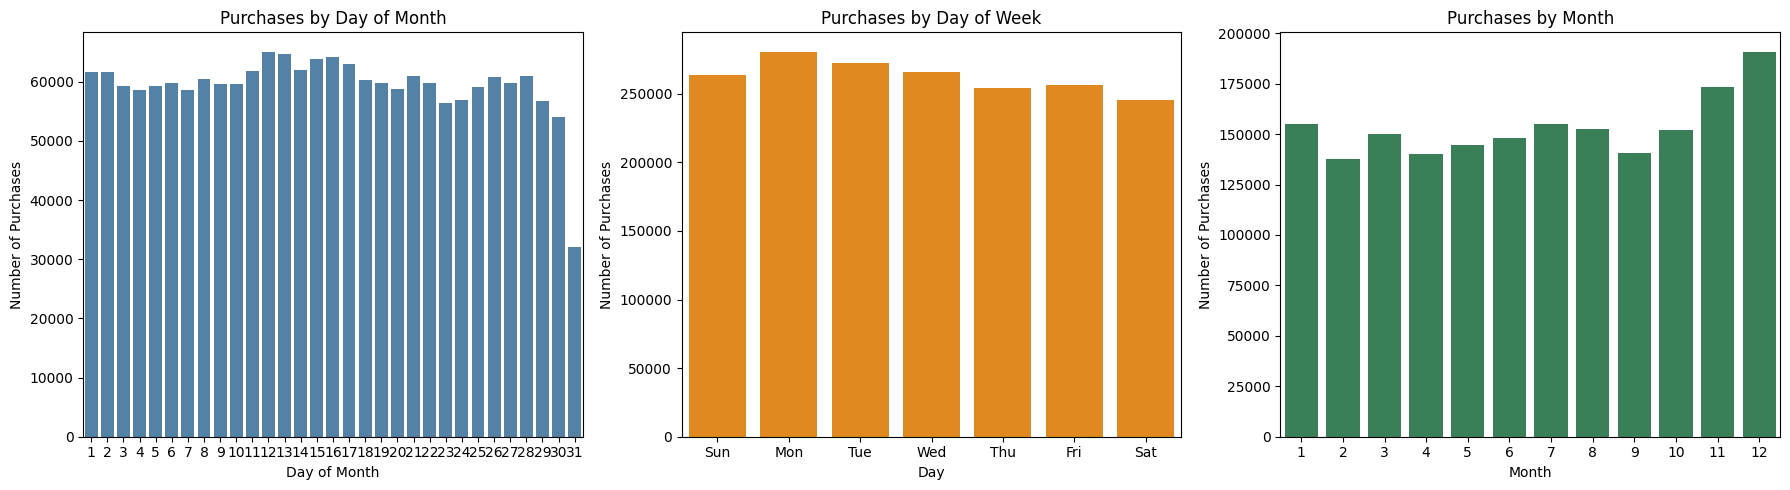

In [73]:
# Purchase Distribution by Hour, Day, and Month

from pyspark.sql.functions import hour, dayofweek, month
import seaborn as sns
import matplotlib.pyplot as plt

# Extract hour, day, and month
# Extract hour, day, and month
time_df = (
    merged_data
    .withColumn("Hour", hour(col("Order Date").cast("timestamp")))
    .withColumn("DayOfWeek", dayofweek(col("Order Date")))     # 1 = Sunday ... 7 = Saturday
    .withColumn("DayOfMonth", dayofmonth(col("Order Date")))
    .withColumn("Month", month(col("Order Date")))
)

# Group and count purchases by time factors
hour_counts = time_df.groupBy("Hour").count().orderBy("Hour")
dow_counts = time_df.groupBy("DayOfWeek").count().orderBy("DayOfWeek")
dom_counts = time_df.groupBy("DayOfMonth").count().orderBy("DayOfMonth")
month_counts = time_df.groupBy("Month").count().orderBy("Month")

# Convert to Pandas for visualisation
hour_pd = hour_counts.toPandas()
dow_pd = dow_counts.toPandas()
dom_pd = dom_counts.toPandas()
month_pd = month_counts.toPandas()

# Label weekdays
day_names = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
dow_pd["Day"] = dow_pd["DayOfWeek"].map(day_names)


# Plot the data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: hour (or day of month if there is no time information)
if hour_pd["Hour"].nunique() > 1:
    sns.barplot(x="Hour", y="count", data=hour_pd, ax=axes[0], color="steelblue")
    axes[0].set_title("Purchases by Hour of Day")
    axes[0].set_xlabel("Hour")
else:
    print("Order Date has no time component, so using day of month instead of hour.")
    sns.barplot(x="DayOfMonth", y="count", data=dom_pd, ax=axes[0], color="steelblue")
    axes[0].set_title("Purchases by Day of Month")
    axes[0].set_xlabel("Day of Month")
axes[0].set_ylabel("Number of Purchases")

# Panel 2: day of week
sns.barplot(x="Day", y="count", data=dow_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Purchases by Day of Week")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Number of Purchases")

# Panel 3: month
sns.barplot(x="Month", y="count", data=month_pd, ax=axes[2], color="seagreen")
axes[2].set_title("Purchases by Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of Purchases")

plt.tight_layout()
plt.show()


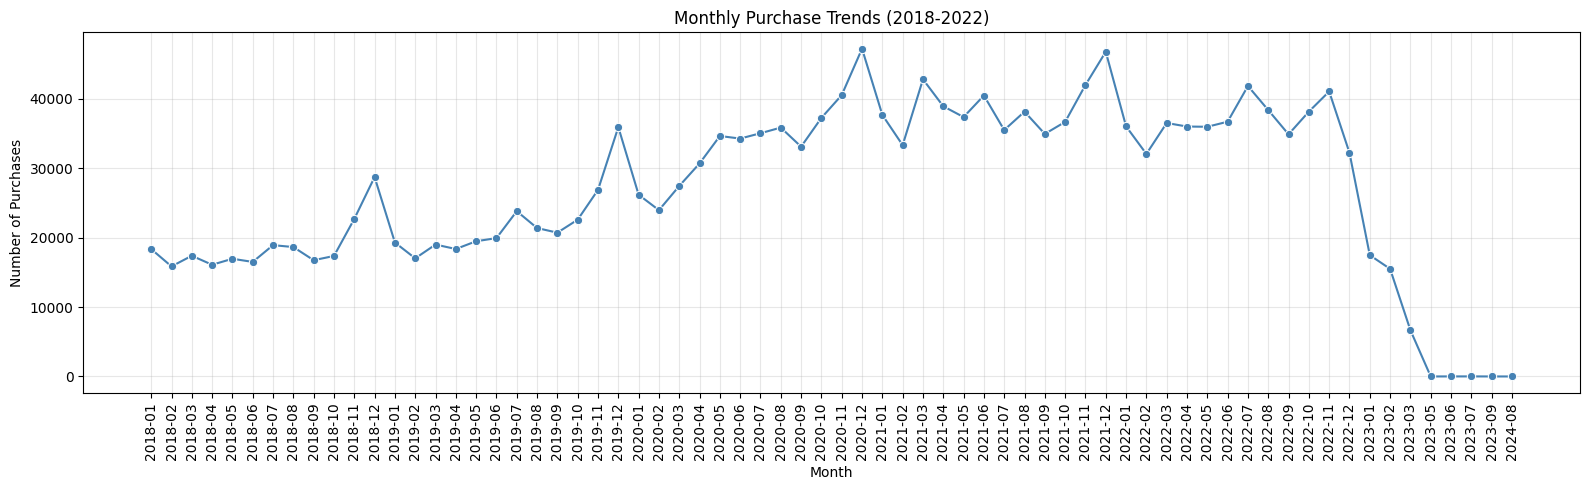

In [74]:
# Monthly Purchase Trends

from pyspark.sql.functions import date_format

# Extract month and year from 'Order Date'
monthly_df = merged_data.withColumn("Year_Month", date_format(col("Order Date"), "yyyy-MM"))

# Group by month and count purchases
monthly_counts = (
    monthly_df
    .groupBy("Year_Month")
    .count()
    .orderBy("Year_Month")
)

# Convert to Pandas for visualisation
monthly_pd = monthly_counts.toPandas()


# Plot
plt.figure(figsize=(16, 5))
sns.lineplot(x="Year_Month", y="count", data=monthly_pd, marker="o", color="steelblue")
plt.title("Monthly Purchase Trends (2018-2022)")
plt.xlabel("Month")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


   Year   count
0  2018  224259
1  2019  264409
2  2020  406211
3  2021  464639
4  2022  439843
5  2023   39660
6  2024       1


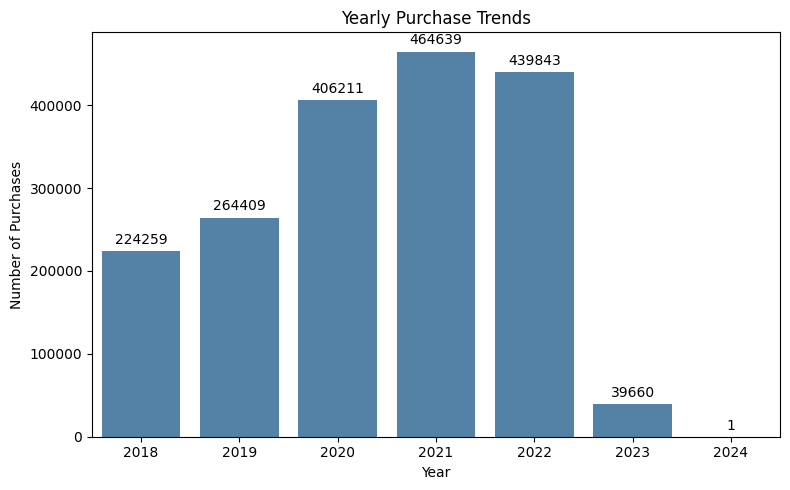

In [75]:
# Yealy Purchase Trends

from pyspark.sql.functions import date_format


# Group by Year and count purchases
yearly_counts = (
    merged_data
    .withColumn("Year", date_format(col("Order Date"), "yyyy"))
    .groupBy("Year")
    .count()
    .orderBy("Year")
)


# Convert to Pandas for visualisation
yearly_pd = yearly_counts.toPandas()
print(yearly_pd)

# Plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(x="Year", y="count", data=yearly_pd, color="steelblue")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.title("Yearly Purchase Trends")
plt.xlabel("Year")
plt.ylabel("Number of Purchases")
plt.tight_layout()
plt.show()


## 3.2 Customer Demographics vs Purchase Frequency <font color = red>[5 marks]</font> <br>
Analyse the trends between the customer deographics and the purchase frequency

        Q-demos-income  Purchases  Customers  Purchases_per_Customer
1    Less than $25,000     170308        685              248.624818
4    $25,000 - $49,999     340599       1189              286.458368
6    $50,000 - $74,999     359696       1063              338.378175
3    $75,000 - $99,999     289491        761              380.408673
2  $100,000 - $149,999     378974        790              479.713924
5     $150,000 or more     241939        463              522.546436
0    Prefer not to say      18715         76              246.250000
      Q-demos-gender  Purchases  Customers  Purchases_per_Customer
0  Prefer not to say       1377         11              125.181818
1             Female    1049440       2589              405.345693
2              Other      32136        116              277.034483
3               Male     716769       2311              310.155344


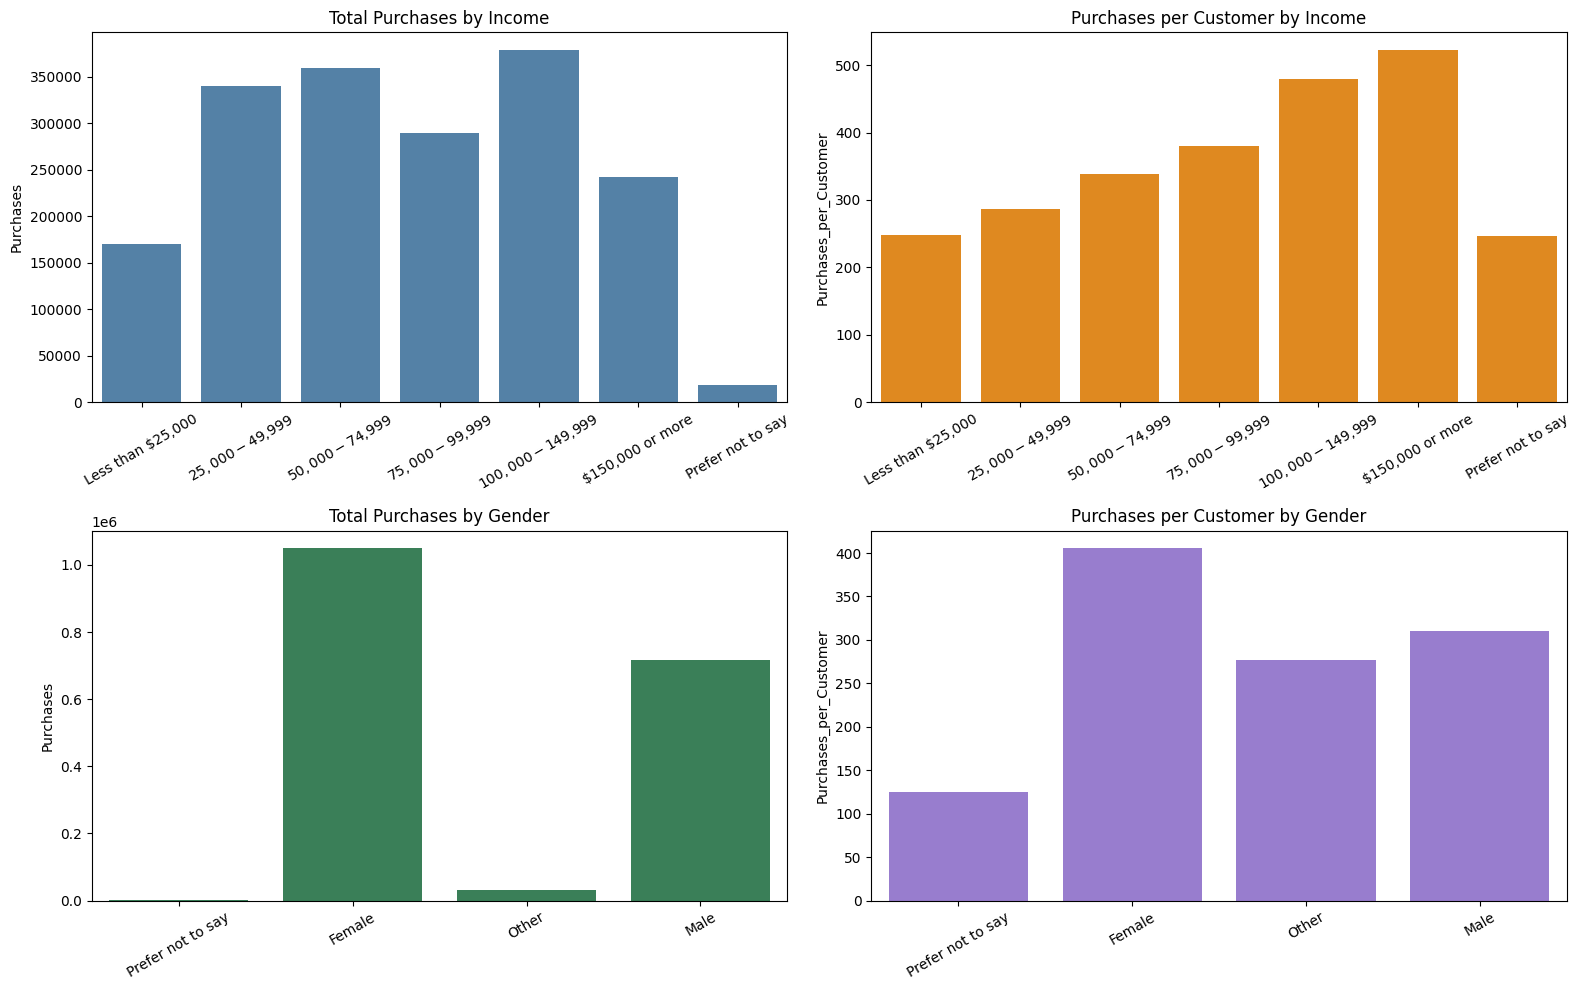

In [76]:
# Correlation Between Demographics and Purchase Frequency

from pyspark.sql.functions import count, countDistinct

# Group by demographic attributes and count purchases
# Exclude customers with no demographic info
demo_df = merged_data.filter(
    (col("Q-demos-income") != "Unknown") & (col("Q-demos-gender") != "Unknown")
)

income_freq = (
    demo_df.groupBy("Q-demos-income")
    .agg(count("*").alias("Purchases"), countDistinct("Survey ResponseID").alias("Customers"))
)
gender_freq = (
    demo_df.groupBy("Q-demos-gender")
    .agg(count("*").alias("Purchases"), countDistinct("Survey ResponseID").alias("Customers"))
)


# Convert to Pandas for visualisation
income_pd = income_freq.toPandas()
gender_pd = gender_freq.toPandas()
# Purchases per customer (fair comparison across group sizes)
income_pd["Purchases_per_Customer"] = income_pd["Purchases"] / income_pd["Customers"]
gender_pd["Purchases_per_Customer"] = gender_pd["Purchases"] / gender_pd["Customers"]

# Order income brackets logically
income_order = [
    "Less than $25,000", "$25,000 - $49,999", "$50,000 - $74,999",
    "$75,000 - $99,999", "$100,000 - $149,999", "$150,000 or more", "Prefer not to say"
]
income_pd["Q-demos-income"] = income_pd["Q-demos-income"].astype("category")
income_pd["Q-demos-income"] = income_pd["Q-demos-income"].cat.set_categories(income_order, ordered=True)
income_pd = income_pd.sort_values("Q-demos-income")

print(income_pd)
print(gender_pd)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.barplot(x="Q-demos-income", y="Purchases", data=income_pd, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Total Purchases by Income")

sns.barplot(x="Q-demos-income", y="Purchases_per_Customer", data=income_pd, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Purchases per Customer by Income")

sns.barplot(x="Q-demos-gender", y="Purchases", data=gender_pd, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Total Purchases by Gender")

sns.barplot(x="Q-demos-gender", y="Purchases_per_Customer", data=gender_pd, ax=axes[1, 1], color="mediumpurple")
axes[1, 1].set_title("Purchases per Customer by Gender")

for ax in axes.flat:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## 3.3 Purchase behavior weekend vs weekday <font color = red>[5 marks]</font> <br>

Compare the purchase behavior of customer's on weekdays vs. weekends.

  Day_Type  Purchases  Total_Revenue  Num_Days  Purchases_per_Day  \
0  Weekday    1329624    32050825.23      1369         971.237400   
1  Weekend     509398    11815804.03       544         936.393382   

   Revenue_per_Day  Avg_Order_Value  
0     23411.851885        24.105180  
1     21720.227996        23.195623  


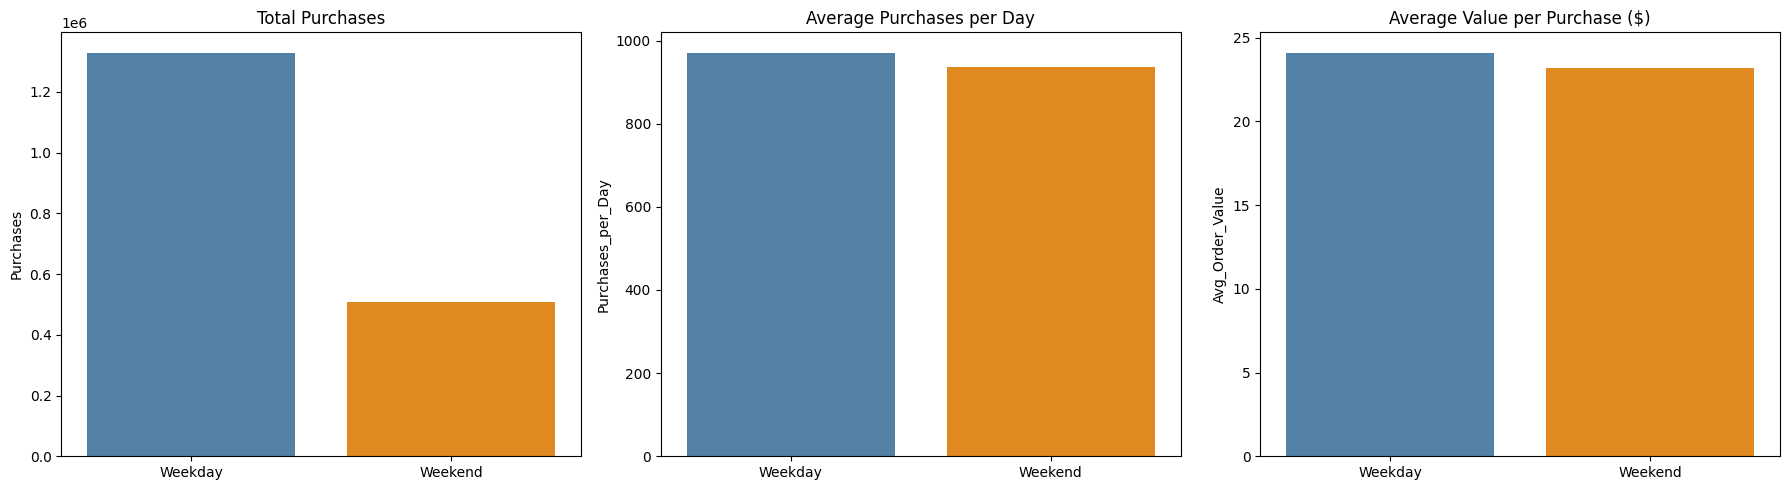

In [77]:
# Weekday vs. Weekend Purchase Behavior

from pyspark.sql.functions import when

# Define weekdays and weekends
day_type_df = merged_data.withColumn(
    "Day_Type",
    when(dayofweek(col("Order Date")).isin(1, 7), "Weekend").otherwise("Weekday")
)

# Group and count purchases
day_type_stats = (
    day_type_df.groupBy("Day_Type")
    .agg(
        count("*").alias("Purchases"),
        spark_sum("Revenue").alias("Total_Revenue"),
        countDistinct("Order Date").alias("Num_Days")
    )
)


# Convert to Pandas for visualisation
day_type_pd = day_type_stats.toPandas()
# Fair comparison: average per calendar day
day_type_pd["Purchases_per_Day"] = day_type_pd["Purchases"] / day_type_pd["Num_Days"]
day_type_pd["Revenue_per_Day"] = day_type_pd["Total_Revenue"] / day_type_pd["Num_Days"]
day_type_pd["Avg_Order_Value"] = day_type_pd["Total_Revenue"] / day_type_pd["Purchases"]
print(day_type_pd)


# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x="Day_Type", y="Purchases", hue="Day_Type", data=day_type_pd, ax=axes[0],
            palette=["steelblue", "darkorange"], legend=False)
axes[0].set_title("Total Purchases")

sns.barplot(x="Day_Type", y="Purchases_per_Day",hue="Day_Type", data=day_type_pd, ax=axes[1], palette=["steelblue", "darkorange"], legend=False)
axes[1].set_title("Average Purchases per Day")

sns.barplot(x="Day_Type", y="Avg_Order_Value", hue="Day_Type",data=day_type_pd, ax=axes[2], palette=["steelblue", "darkorange"], legend=False)
axes[2].set_title("Average Value per Purchase ($)")

for ax in axes:
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

## 3.4 Frequently purchased product pairs <font color = red>[5 marks]</font> <br>

Analyze how frequently products are purchased together (also known as Market Basket Analysis)


Baskets with 2-10 distinct items: 350643
                                                Pair  count
0  Amazon Basics 36 Pack AAA High-Performan  +  A...    113
1  Amazon Music Unlimited  +  Echo Dot (3rd Gen, ...     82
2  Group Gift Wedding Contribution  +  Group Gift...     79
3  $10 -PlayStation Store Gift Card [Digita  +  $...     78
4  $20 Nintendo eShop Gift Card [Digital Co  +  $...     45
5  Amazon.com Gift Card Balance Reload  +  Google...     45
6  $10 Nintendo eShop Gift Card [Digital Co  +  $...     37
7  Amazon Basics 20 Pack AA High-Performanc  +  A...     36
8  Amazon.com Gift Card Balance Reload  +  Amazon...     34
9  $10 Nintendo eShop Gift Card [Digital Co  +  $...     34


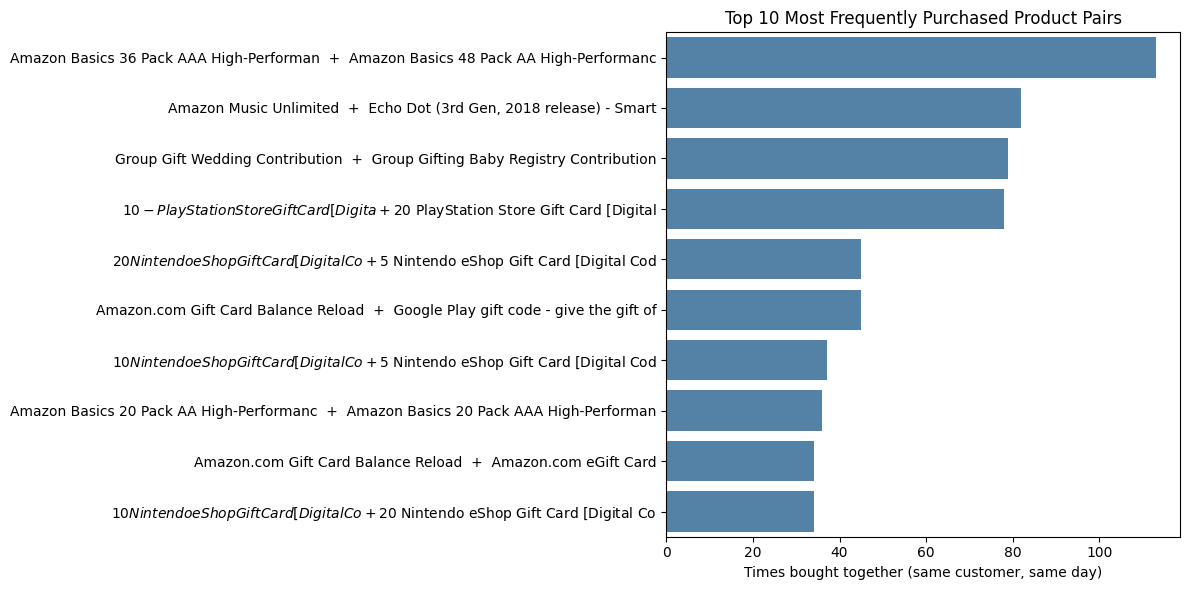

In [78]:
# Frequently Purchased Product Pairs (Market Basket Analysis)

from pyspark.sql.functions import collect_set, explode, array_sort, expr, substring, size

# Group purchases by customer and collect items bought together

baskets = (
    merged_data
    .filter(col("Title") != "Unknown")
    .groupBy("Survey ResponseID", "Order Date")
    .agg(collect_set("Title").alias("items"))
    .withColumn("items", array_sort(col("items")))   # sorted so (A,B) and (B,A) are the same pair
    .filter((size("items") >= 2) & (size("items") <= 10))  # need 2+ items; cap to avoid blow-up
)
print("Baskets with 2-10 distinct items:", baskets.count())

# Explode item pairs
pairs = (
    baskets
    .withColumn(
        "pair",
        expr("""
            flatten(
                transform(
                    sequence(0, size(items) - 2),
                    i -> transform(
                        sequence(i + 1, size(items) - 1),
                        j -> array(items[i], items[j])
                    )
                )
            )
        """)
    )
    .select(explode("pair").alias("pair"))
    .select(col("pair")[0].alias("Item_A"), col("pair")[1].alias("Item_B"))
)

# Count co-occurrences of items
pair_counts = (
    pairs.groupBy("Item_A", "Item_B")
    .count()
    .orderBy(col("count").desc())
    .limit(10)
)

# Convert to Pandas for visualisation
pairs_pd = pair_counts.toPandas()
pairs_pd["Pair"] = (
    pairs_pd["Item_A"].str[:40] + "  +  " + pairs_pd["Item_B"].str[:40]
)
print(pairs_pd[["Pair", "count"]])

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(y="Pair", x="count", data=pairs_pd, color="steelblue")
plt.title("Top 10 Most Frequently Purchased Product Pairs")
plt.xlabel("Times bought together (same customer, same day)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 3.5 Examine Product Performance <font color = red>[5 marks]</font> <br>

Examine the performance of products by calculating revenue and item popularity.

                        Category  Total_Revenue  Units_Sold  Revenue_Share_%
0                      ABIS_BOOK     1347983.40       91302         3.244217
1                      GIFT_CARD      866770.53       24187         2.086073
2                       PET_FOOD      762142.81       44615         1.834263
3         NUTRITIONAL_SUPPLEMENT      619691.61       28704         1.491423
4                          SHOES      576032.46       12822         1.386348
5                     HEADPHONES      543938.97       11870         1.309108
6                          SHIRT      512128.82       28007         1.232550
7                          PANTS      406391.73       16625         0.978070
8              NOTEBOOK_COMPUTER      321789.22         599         0.774456
9           HEALTH_PERSONAL_CARE      306175.84       17711         0.736879
10                CELLULAR_PHONE      285067.97        1101         0.686078
11     COMPUTER_DRIVE_OR_STORAGE      273580.96        2974         0.658432

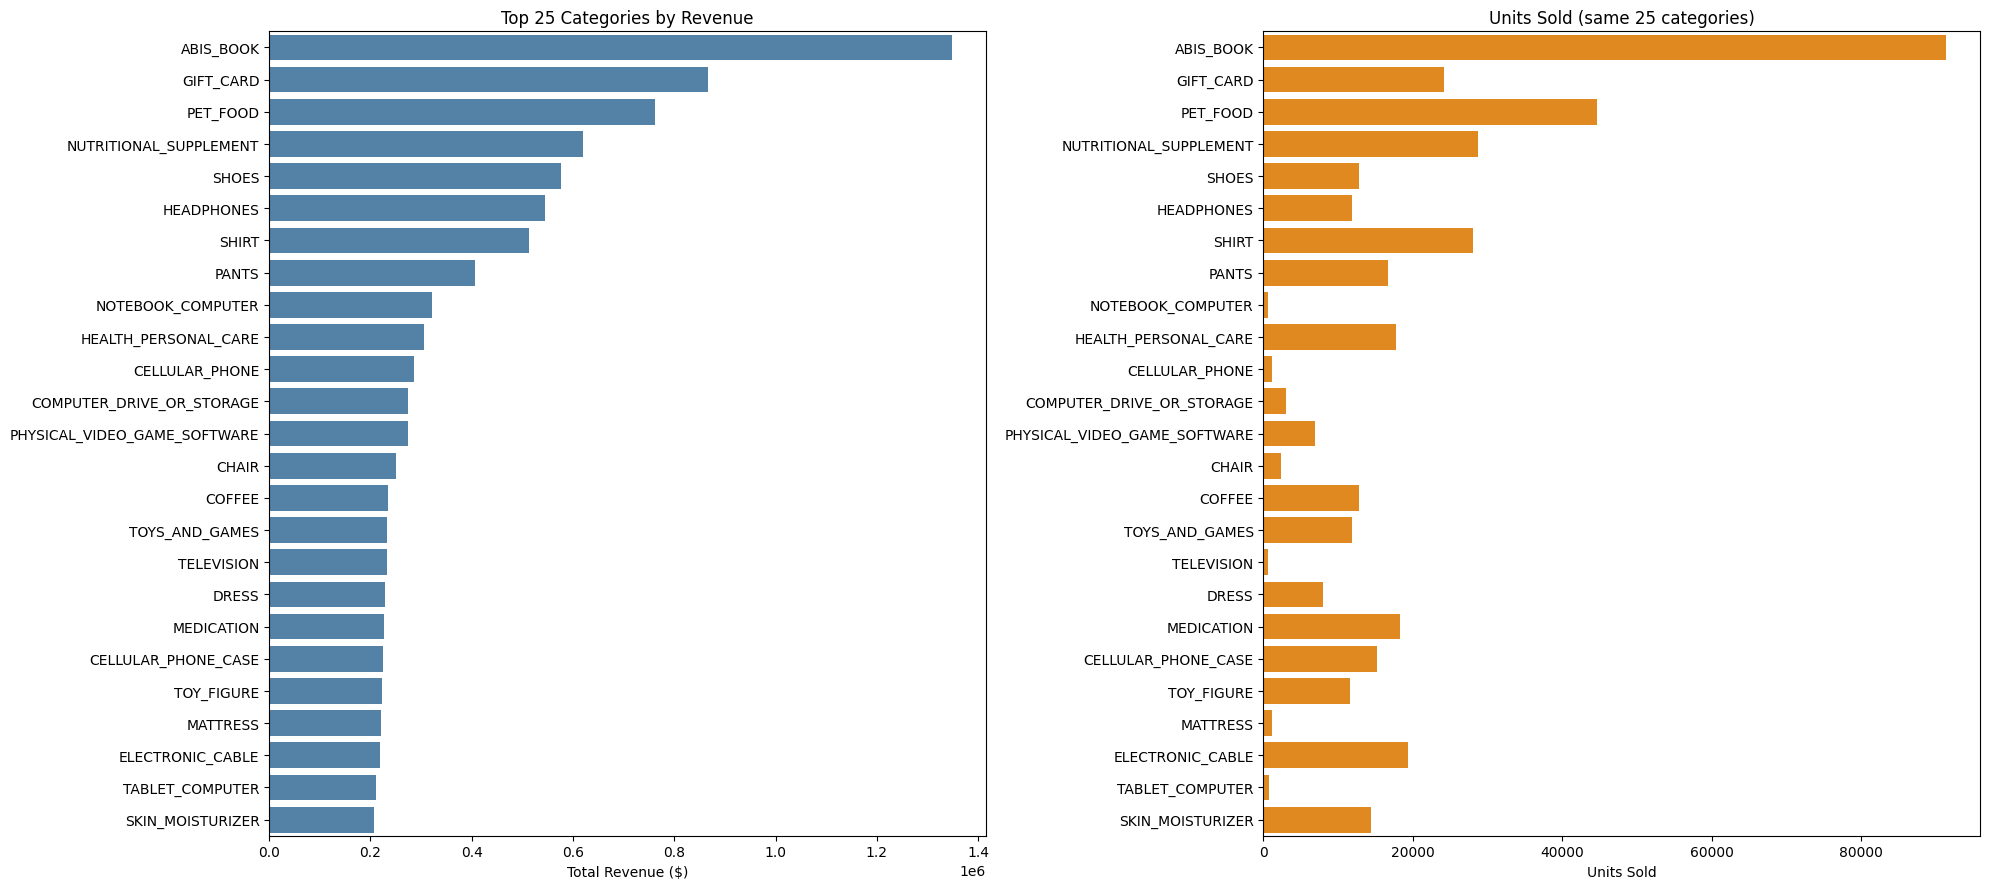

In [79]:
# Contribution of Product Categories (Top 25)
# Revenue and popularity per category
category_perf = (
    merged_data
    .filter(col("Category") != "Unknown")
    .groupBy("Category")
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        spark_sum("Quantity").alias("Units_Sold"),
        count("*").alias("Num_Purchases")
    )
    .orderBy(col("Total_Revenue").desc())
    .limit(25)
)


# Convert to Pandas for visualisation
category_pd = category_perf.toPandas()
# Share of total revenue (computed against ALL categories, not just the top 25)
total_revenue = merged_data.filter(col("Category") != "Unknown").agg(spark_sum("Revenue")).collect()[0][0]
category_pd["Revenue_Share_%"] = category_pd["Total_Revenue"] / total_revenue * 100
print(category_pd[["Category", "Total_Revenue", "Units_Sold", "Revenue_Share_%"]])
print(f"Top 25 categories contribute {category_pd['Revenue_Share_%'].sum():.1f}% of total revenue")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

sns.barplot(y="Category", x="Total_Revenue", data=category_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Top 25 Categories by Revenue")
axes[0].set_xlabel("Total Revenue ($)")
axes[0].set_ylabel("")

sns.barplot(y="Category", x="Units_Sold", data=category_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Units Sold (same 25 categories)")
axes[1].set_xlabel("Units Sold")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 3.6 Top products by quantity <font color = red>[5 marks]</font> <br>

Identify the most frequently purchased products.

                                         Short_Title  Total_Quantity  \
0                Amazon.com Gift Card Balance Reload            8282   
1                              Amazon.com eGift Card            5179   
2                                      Amazon Reload            4876   
3        Photo Prints – Glossy – Standard Size (4x6)            2336   
4      Photo Prints – Glossy – Standard Size (4x5.3)            1833   
5  Google Play gift code - give the gift of games...             835   
6         Photo Prints – Matte – Standard Size (4x6)             761   
7    $10 -PlayStation Store Gift Card [Digital Code]             652   
8  Bring | Teach | Keep: Illuminating the Biblica...             635   
9                                                  1             605   

   Total_Revenue  Num_Purchases  
0      226175.22           8282  
1      215947.95           4682  
2      117078.49           4876  
3         332.92             86  
4         233.37             50  
5  

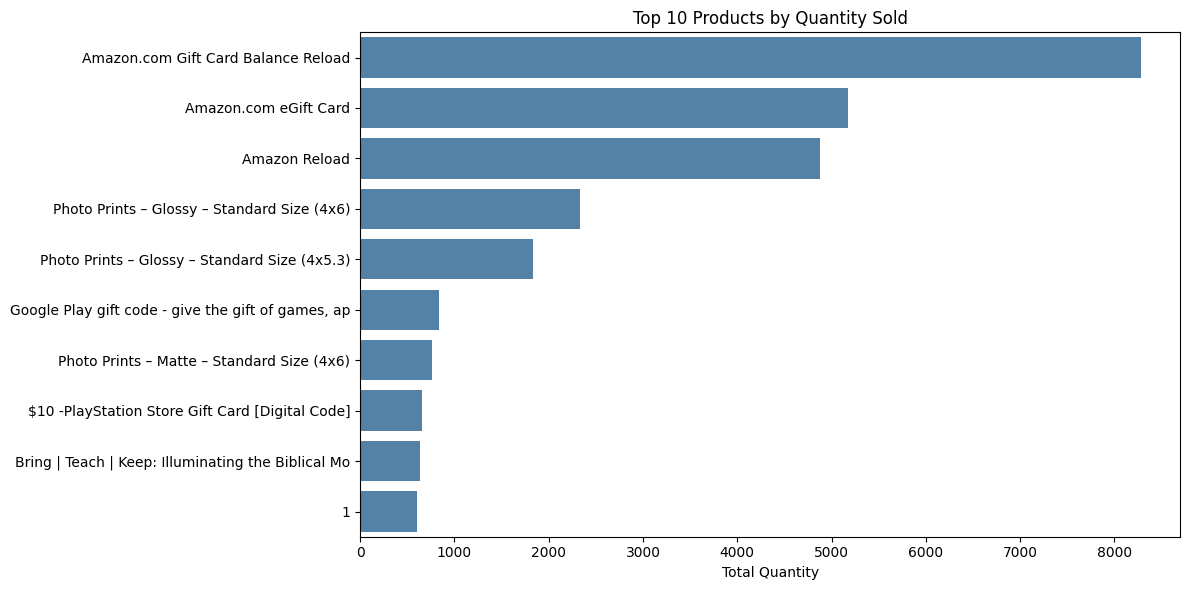

In [80]:
# Top 10 Products by Quantity

# Group by product title and sum 'Quantity'
top_products = (
    merged_data
    .filter(col("Title") != "Unknown")
    .groupBy("Title")
    .agg(
        spark_sum("Quantity").alias("Total_Quantity"),
        spark_sum("Revenue").alias("Total_Revenue"),
        count("*").alias("Num_Purchases")
    )
    .orderBy(col("Total_Quantity").desc())
    .limit(10)
)

# Convert to Pandas for visualisation
top_products_pd = top_products.toPandas()
top_products_pd["Short_Title"] = top_products_pd["Title"].str[:50]
print(top_products_pd[["Short_Title", "Total_Quantity", "Total_Revenue", "Num_Purchases"]])


# Plot
plt.figure(figsize=(12, 6))
sns.barplot(y="Short_Title", x="Total_Quantity", data=top_products_pd, color="steelblue")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 3.7 Distribution of Purchases by State <font color = red>[5 marks]</font> <br>

Analyze the distribution of purchases across states and categories.

   Shipping Address State  Num_Purchases  Total_Revenue
0                      CA         178088     4320755.40
1                      TX         135596     3247992.54
2                      FL         110414     2671910.96
3                      NY         103557     2358050.43
4                      PA          96760     2194848.51
5                      OH          86247     1956486.23
6                      IL          71396     1734260.97
7                      NC          71269     1686451.07
8                      MI          60329     1404837.13
9                      WA          53172     1172561.82
10                     GA          52818     1228032.13
11                     VA          50533     1197928.52
12                     NJ          45862     1069863.05
13                     MA          44399     1086615.44
14                     IN          43608      992326.57
15                     WI          37202      914765.29
16                     OR          36328      87

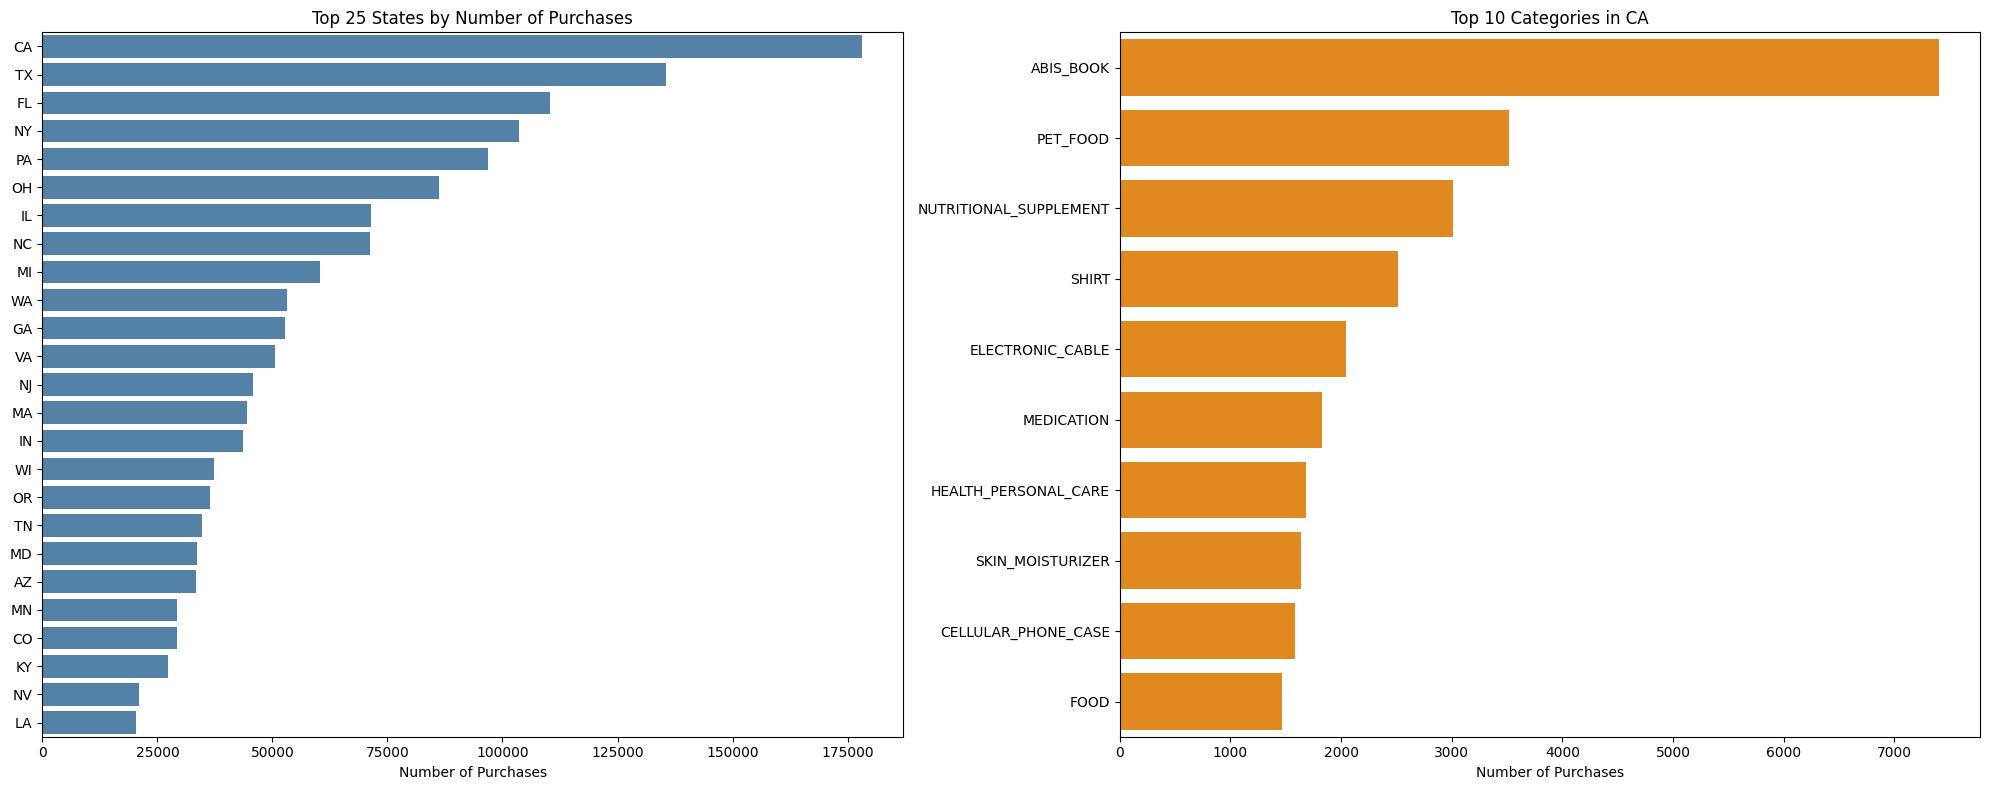

In [81]:
# Distribution of Purchases by State (Top 25)
state_dist = (
    merged_data
    .filter(col("Shipping Address State") != "Unknown")
    .groupBy("Shipping Address State")
    .agg(
        count("*").alias("Num_Purchases"),
        spark_sum("Revenue").alias("Total_Revenue")
    )
    .orderBy(col("Num_Purchases").desc())
    .limit(25)
)

# Convert to Pandas for visualisation
state_pd = state_dist.toPandas()
print(state_pd)

# Top categories inside the #1 state (covers the "and categories" part of the task)
top_state = state_pd.iloc[0]["Shipping Address State"]
state_cat_pd = (
    merged_data
    .filter((col("Shipping Address State") == top_state) & (col("Category") != "Unknown"))
    .groupBy("Category")
    .agg(count("*").alias("Num_Purchases"))
    .orderBy(col("Num_Purchases").desc())
    .limit(10)
    .toPandas()
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.barplot(y="Shipping Address State", x="Num_Purchases", data=state_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Top 25 States by Number of Purchases")
axes[0].set_xlabel("Number of Purchases")
axes[0].set_ylabel("")

sns.barplot(y="Category", x="Num_Purchases", data=state_cat_pd, ax=axes[1], color="darkorange")
axes[1].set_title(f"Top 10 Categories in {top_state}")
axes[1].set_xlabel("Number of Purchases")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 3.8 Price vs Product Quantity <font color = red>[5 marks]</font> <br>

Identify the Relationship between Price and Quantity

Correlation (price vs quantity): -0.0242
Correlation (log price vs quantity): -0.0867
    Price_Band  Avg_Quantity  Num_Purchases
0      1. <$10      1.154825         636319
1    2. $10-25      1.059836         797917
2    3. $25-50      1.043799         283477
3   4. $50-100      1.040815          77300
4  5. $100-250      1.039502          34403
5     6. $250+      1.025088           9606


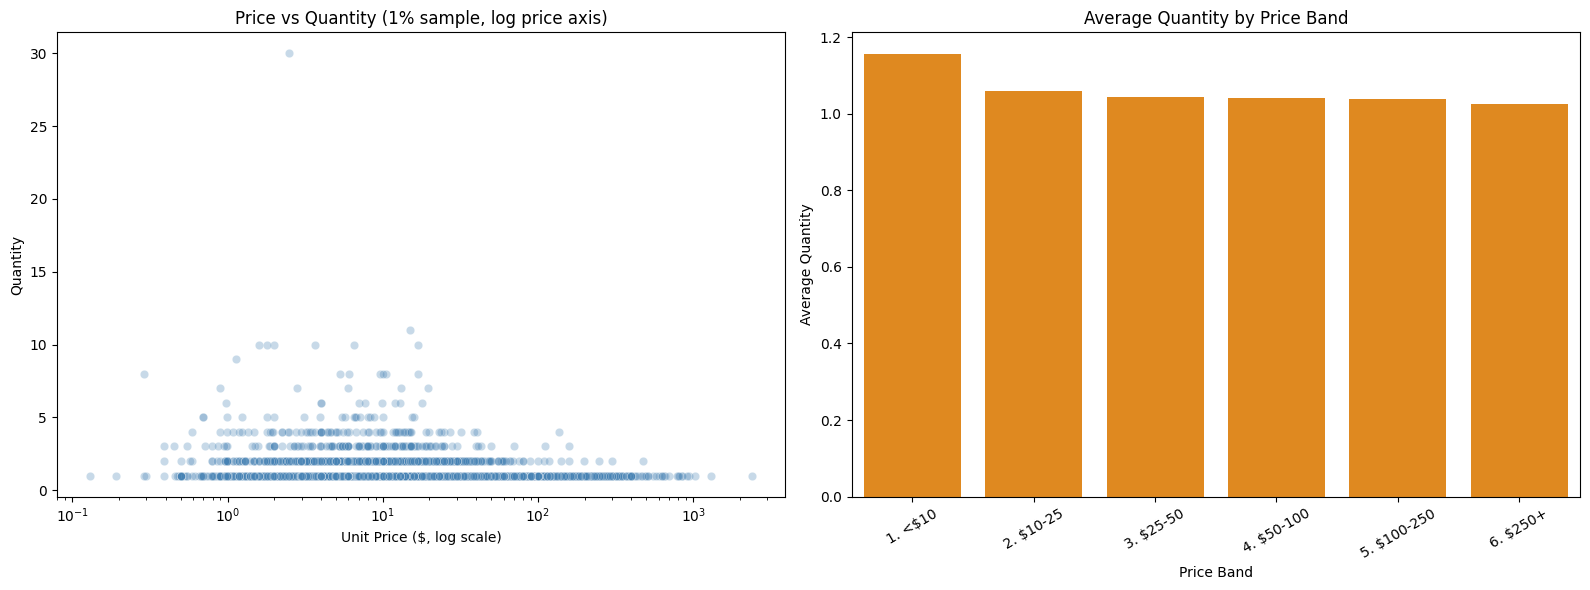

In [82]:
# Relationship Between Price and Quantity
from pyspark.sql.functions import corr, avg

price_col = "Purchase Price Per Unit"

# Keep valid rows only (positive price and quantity)
pq_df = merged_data.filter((col(price_col) > 0) & (col("Quantity") > 0))

# Correlation on the full dataset (Pearson, and on log-price for a skew-robust view)
from pyspark.sql.functions import log1p
corr_raw = pq_df.stat.corr(price_col, "Quantity")
corr_log = pq_df.withColumn("log_price", log1p(col(price_col))).stat.corr("log_price", "Quantity")
print(f"Correlation (price vs quantity): {corr_raw:.4f}")
print(f"Correlation (log price vs quantity): {corr_log:.4f}")

# Average quantity by price band (shows the pattern more clearly than a raw scatter)
banded = (
    pq_df.withColumn(
        "Price_Band",
        when(col(price_col) < 10, "1. <$10")
        .when(col(price_col) < 25, "2. $10-25")
        .when(col(price_col) < 50, "3. $25-50")
        .when(col(price_col) < 100, "4. $50-100")
        .when(col(price_col) < 250, "5. $100-250")
        .otherwise("6. $250+")
    )
    .groupBy("Price_Band")
    .agg(avg("Quantity").alias("Avg_Quantity"), count("*").alias("Num_Purchases"))
    .orderBy("Price_Band")
)


# Convert to Pandas for visualisation
sample_pd = pq_df.select(price_col, "Quantity").sample(fraction=0.01, seed=42).toPandas()
band_pd = banded.toPandas()
print(band_pd)


# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=price_col, y="Quantity", data=sample_pd, alpha=0.3, ax=axes[0], color="steelblue")
axes[0].set_xscale("log")
axes[0].set_title("Price vs Quantity (1% sample, log price axis)")
axes[0].set_xlabel("Unit Price ($, log scale)")
axes[0].set_ylabel("Quantity")

sns.barplot(x="Price_Band", y="Avg_Quantity", data=band_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Average Quantity by Price Band")
axes[1].set_xlabel("Price Band")
axes[1].set_ylabel("Average Quantity")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 3.9 Analyse the spending KPIs <font color = red>[5 marks]</font> <br>


A popular KPI is average spend per customer. Calculate this metric as the ratio of total transaction amount from non-recurring payments divided by the total number of customers who made a purchase

Total revenue: $43,866,629.26
Customers who purchased: 16,072
Average spend per customer: $2,729.38
count     16071.000000
mean       2729.408046
std        6535.752728
min           0.010000
25%          17.880000
50%          55.950000
75%        1928.165000
max      112348.360000
Name: Total_Spend, dtype: float64


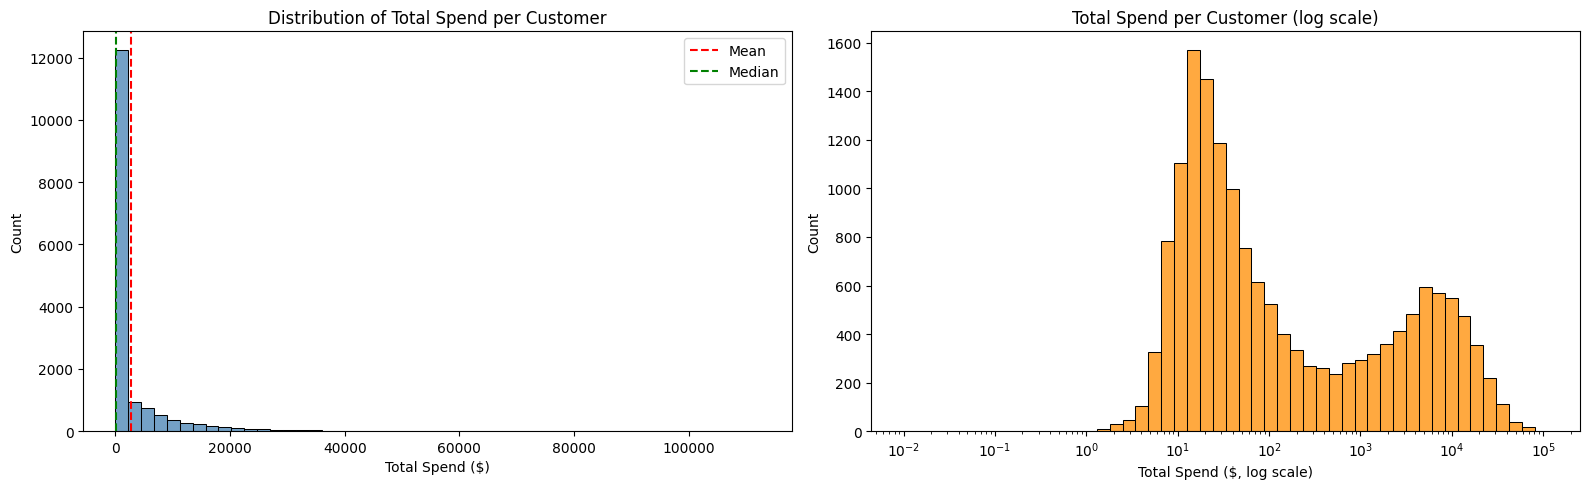

In [83]:
# Average Spend per Customer

from pyspark.sql.functions import avg

# Group by customer and calculate average spend
customer_spend = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(spark_sum("Revenue").alias("Total_Spend"))
)

# Headline KPI: total revenue / number of purchasing customers
total_revenue = merged_data.agg(spark_sum("Revenue")).collect()[0][0]
num_customers = merged_data.agg(countDistinct("Survey ResponseID")).collect()[0][0]
avg_spend = total_revenue / num_customers
print(f"Total revenue: ${total_revenue:,.2f}")
print(f"Customers who purchased: {num_customers:,}")
print(f"Average spend per customer: ${avg_spend:,.2f}")

# Convert to Pandas for visualisation
spend_pd = customer_spend.toPandas()
print(spend_pd["Total_Spend"].describe())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(spend_pd["Total_Spend"], bins=50, ax=axes[0], color="steelblue")
axes[0].axvline(spend_pd["Total_Spend"].mean(), color="red", linestyle="--", label="Mean")
axes[0].axvline(spend_pd["Total_Spend"].median(), color="green", linestyle="--", label="Median")
axes[0].set_title("Distribution of Total Spend per Customer")
axes[0].set_xlabel("Total Spend ($)")
axes[0].legend()

sns.histplot(spend_pd["Total_Spend"], bins=50, log_scale=True, ax=axes[1], color="darkorange")
axes[1].set_title("Total Spend per Customer (log scale)")
axes[1].set_xlabel("Total Spend ($, log scale)")

plt.tight_layout()
plt.show()

Analyse the Repeat Purchase Behavior of Customers

          Num_Items  Num_Order_Days
count  16071.000000    16071.000000
mean     114.422127       53.034721
std      284.420525      116.870485
min        1.000000        1.000000
25%        1.000000        1.000000
50%        2.000000        2.000000
75%       75.000000       41.000000
max     5258.000000     1258.000000
Customer_Type
One-time                  7402
Occasional (2-10 days)    3374
Regular (11-50 days)      1535
Frequent (50+ days)       3760
Name: count, dtype: int64
Repeat purchase rate (2+ order days): 53.9%


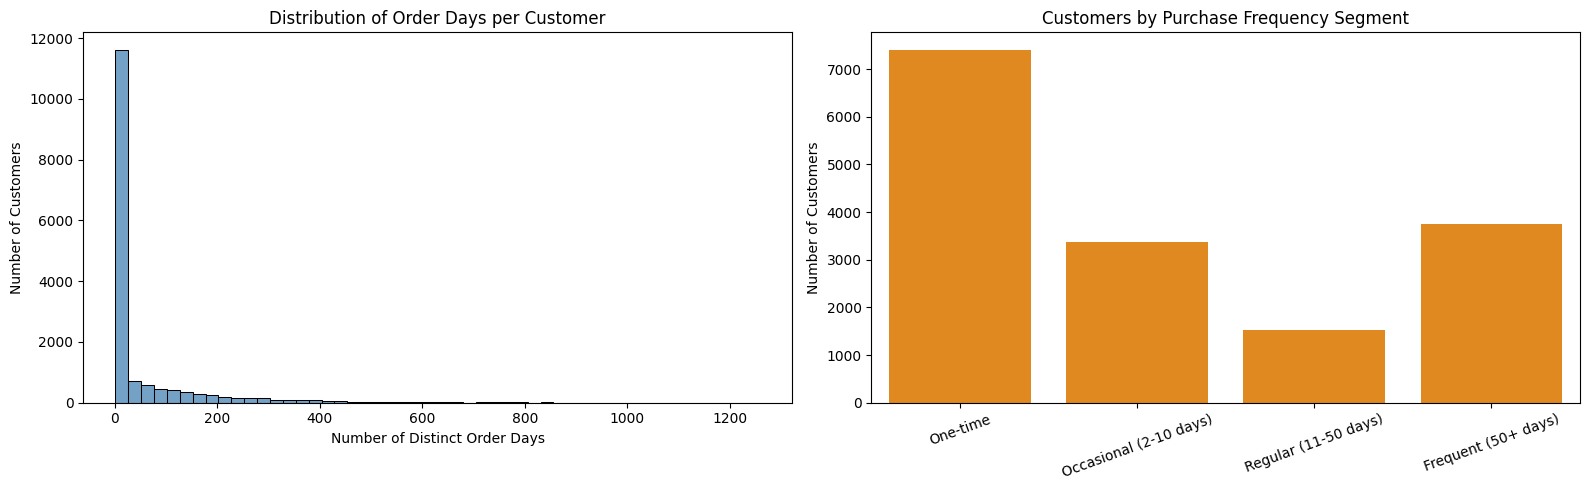

In [84]:
# Repeat Purchase Analysis Behavior Per Customers
repeat_df = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(
        count("*").alias("Num_Items"),
        countDistinct("Order Date").alias("Num_Order_Days")
    )
    .withColumn(
        "Customer_Type",
        when(col("Num_Order_Days") == 1, "One-time")
        .when(col("Num_Order_Days") <= 10, "Occasional (2-10 days)")
        .when(col("Num_Order_Days") <= 50, "Regular (11-50 days)")
        .otherwise("Frequent (50+ days)")
    )
)

# Convert to Pandas for visualisation
repeat_pd = repeat_df.toPandas()
print(repeat_pd[["Num_Items", "Num_Order_Days"]].describe())

type_order = ["One-time", "Occasional (2-10 days)", "Regular (11-50 days)", "Frequent (50+ days)"]
type_counts = repeat_pd["Customer_Type"].value_counts().reindex(type_order).fillna(0)
print(type_counts)
repeat_rate = (repeat_pd["Num_Order_Days"] > 1).mean() * 100
print(f"Repeat purchase rate (2+ order days): {repeat_rate:.1f}%")


# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(repeat_pd["Num_Order_Days"], bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Order Days per Customer")
axes[0].set_xlabel("Number of Distinct Order Days")
axes[0].set_ylabel("Number of Customers")

sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[1], color="darkorange")
axes[1].set_title("Customers by Purchase Frequency Segment")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of Customers")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Analyse the top 10 high-engagement customers

   Survey ResponseID  Num_Items  Num_Order_Days  Total_Spend Customer
0  R_8CXcySQawXPuJwJ       5258             904     76590.78   XPuJwJ
1  R_24csoaO569P4Yzz       4675            1168     74143.63   9P4Yzz
2  R_2EglJpTWGEiwQYa       4185            1258    112348.36   EiwQYa
3  R_1QtQEfi1VAWgRM0       3825             861     73087.99   AWgRM0
4  R_3e5g4lvddcnjkoZ       3815             963     61932.98   cnjkoZ
5  R_1PUcgnVG2i0EBz4       3339             644     53285.68   i0EBz4
6  R_32UZncFA03IrQwQ       2931             873     66635.34   3IrQwQ
7  R_1rwrLVr6jBONnIg       2923             847     63398.50   BONnIg
8  R_3R4b0PxgHJiXxVD       2875            1105     71988.05   JiXxVD
9  R_bJI8lmXMZWL6oql       2856             850     38525.75   WL6oql


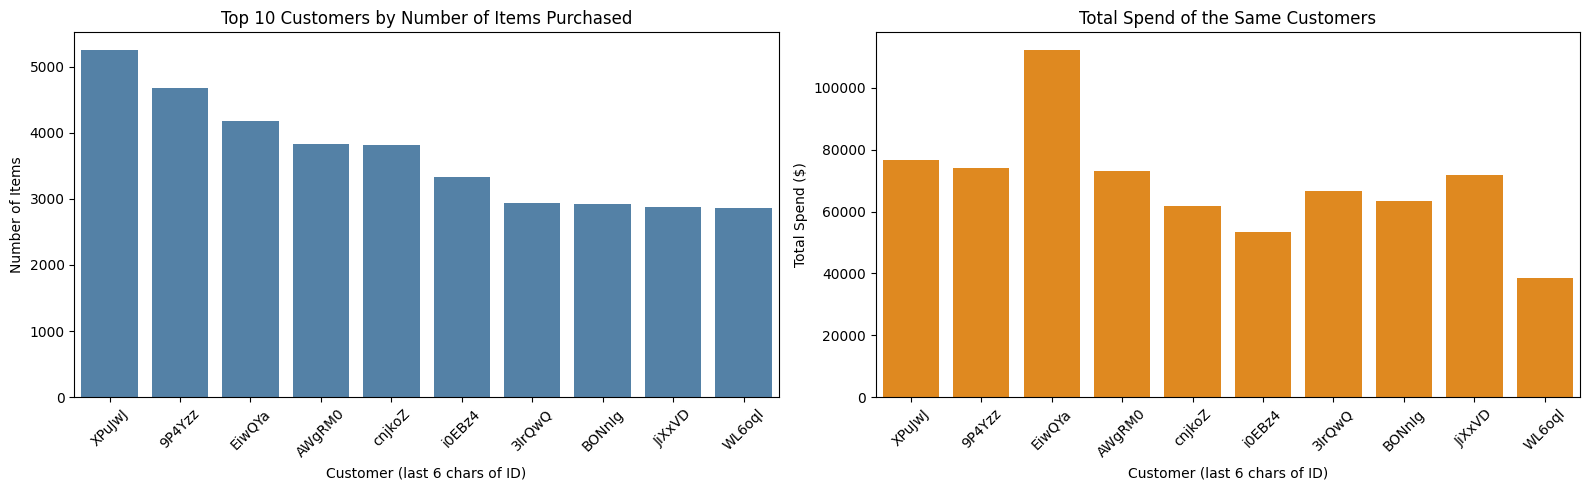

In [85]:
# Top 10 High-Engagement Customers
engagement = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(
        count("*").alias("Num_Items"),
        countDistinct("Order Date").alias("Num_Order_Days"),
        spark_sum("Revenue").alias("Total_Spend")
    )
    .orderBy(col("Num_Items").desc())
    .limit(10)
)

# Convert to Pandas for visualisation
top_cust_pd = engagement.toPandas()
top_cust_pd["Customer"] = top_cust_pd["Survey ResponseID"].str[-6:]   # shortened ID for readable labels
print(top_cust_pd)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x="Customer", y="Num_Items", data=top_cust_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Customers by Number of Items Purchased")
axes[0].set_xlabel("Customer (last 6 chars of ID)")
axes[0].set_ylabel("Number of Items")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(x="Customer", y="Total_Spend", data=top_cust_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Total Spend of the Same Customers")
axes[1].set_xlabel("Customer (last 6 chars of ID)")
axes[1].set_ylabel("Total Spend ($)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 3.10 Seasonal trends in product purchases and their impact on revenues <font color = red>[5 marks]</font> <br>

Investigate the seasonal trends in product purchases and their impact on the overall revenue.

    Month  Total_Revenue  Num_Purchases  Revenue_Share_%
0       1     3532134.59         155018         8.051985
1       2     3206574.68         137722         7.309827
2       3     3567831.74         149835         8.133362
3       4     3314049.89         140082         7.554831
4       5     3458697.16         144432         7.884575
5       6     3638330.99         147892         8.294075
6       7     3824211.37         155135         8.717815
7       8     3519654.94         152415         8.023536
8       9     3199628.27         140400         7.293992
9      10     3606429.48         152040         8.221351
10     11     4412152.14         173173        10.058106
11     12     4586934.01         190878        10.456545


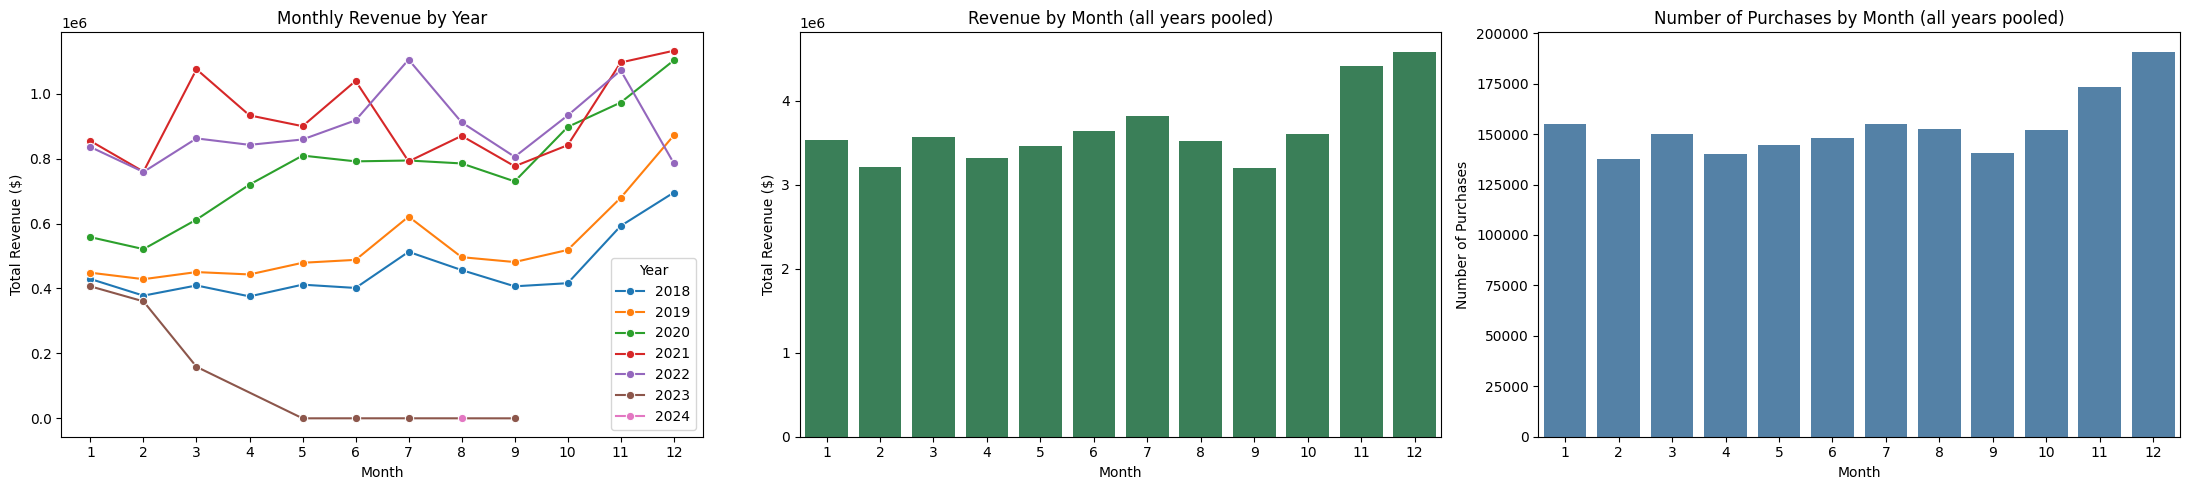

In [86]:
# Seasonal Trends in Product Purchases and Their Impact on Revenue

from pyspark.sql.functions import year

# Extract year and month
season_df = (
    merged_data
    .withColumn("Year", year(col("Order Date")))
    .withColumn("Month", month(col("Order Date")))
)

# Group by year and month, summing total revenue
monthly_rev = (
    season_df.groupBy("Year", "Month")
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        count("*").alias("Num_Purchases")
    )
    .orderBy("Year", "Month")
)

# Pooled across years: average month-of-year pattern
month_pooled = (
    season_df.groupBy("Month")
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        count("*").alias("Num_Purchases")
    )
    .orderBy("Month")
)

# Convert to Pandas for visualisation
monthly_pd = monthly_rev.toPandas()
pooled_pd = month_pooled.toPandas()
pooled_pd["Revenue_Share_%"] = pooled_pd["Total_Revenue"] / pooled_pd["Total_Revenue"].sum() * 100
print(pooled_pd)


# Plot
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

# Panel 1: revenue by month, one line per year
sns.lineplot(x="Month", y="Total_Revenue", hue="Year", data=monthly_pd,
             marker="o", palette="tab10", ax=axes[0])
axes[0].set_title("Monthly Revenue by Year")
axes[0].set_xticks(range(1, 13))
axes[0].set_ylabel("Total Revenue ($)")

# Panel 2: pooled revenue by month of year
sns.barplot(x="Month", y="Total_Revenue", data=pooled_pd, color="seagreen", ax=axes[1])
axes[1].set_title("Revenue by Month (all years pooled)")
axes[1].set_ylabel("Total Revenue ($)")

# Panel 3: pooled purchases by month of year
sns.barplot(x="Month", y="Num_Purchases", data=pooled_pd, color="steelblue", ax=axes[2])
axes[2].set_title("Number of Purchases by Month (all years pooled)")
axes[2].set_ylabel("Number of Purchases")

plt.tight_layout()
plt.show()

## 3.11 Customer location vs purchasing behavior <font color = red>[5 marks]</font> <br>

Examine the relationship between customer's location and their purchasing behaviors

   Shipping Address State  Total_Revenue  Num_Customers  Spend_per_Customer
16                     CA     4320649.55           2932         1473.618537
39                     TX     3247923.91           2374         1368.122961
44                     FL     2671650.28           2162         1235.730934
38                     NY     2357981.83           1783         1322.479994
36                     PA     2194752.20           1635         1342.356086
32                     OH     1956428.12           1544         1267.116658
25                     IL     1734213.22           1337         1297.092909
20                     NC     1686334.55           1361         1239.040816
12                     MI     1404837.13           1273         1103.564124
41                     GA     1227950.65           1112         1104.272167
7                      VA     1197851.91           1134         1056.306799
27                     WA     1172543.88           1044         1123.126322
42          

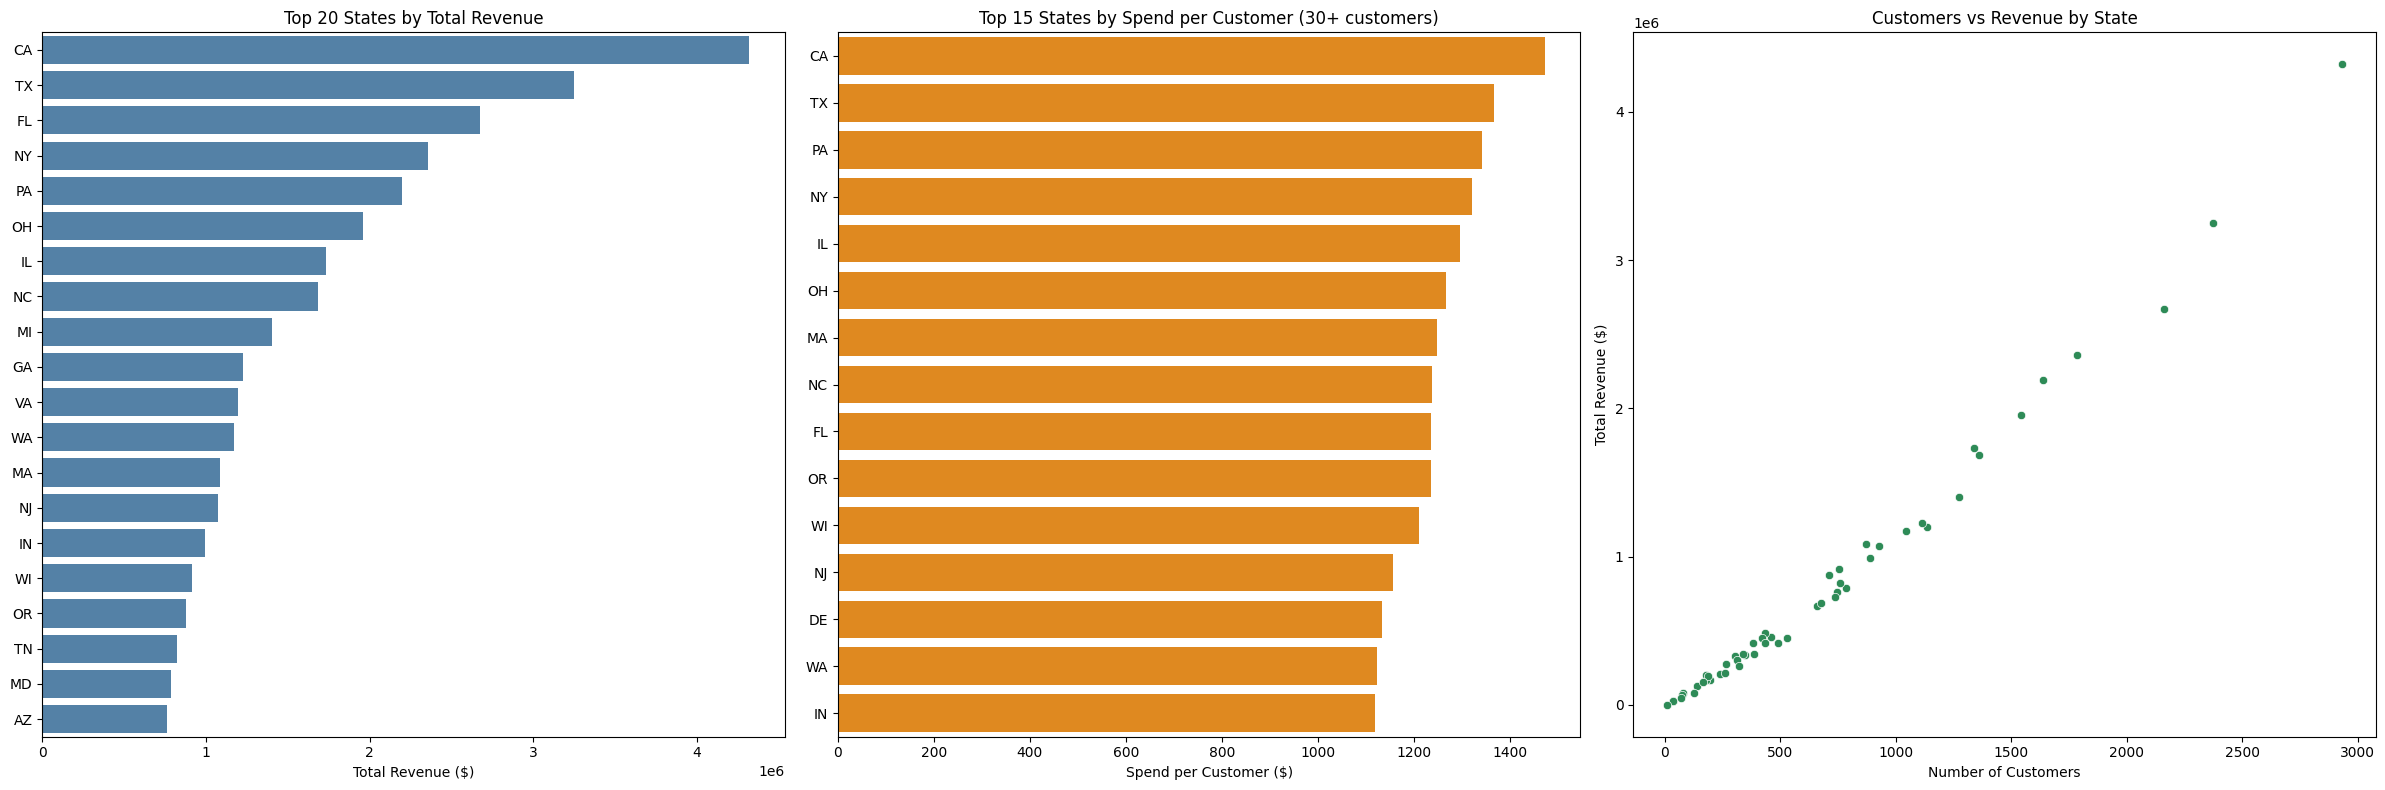

In [87]:
# Relationship Between Customer Location and Purchase Behavior
state_col = "Shipping Address State"

# Group purchases by state and total spend
state_behavior = (
    merged_data
    .filter((col(state_col) != "Unknown") & (col("Survey ResponseID") != "Unknown"))
    .groupBy(state_col)
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        count("*").alias("Num_Purchases"),
        countDistinct("Survey ResponseID").alias("Num_Customers")
    )
    .withColumn("Spend_per_Customer", col("Total_Revenue") / col("Num_Customers"))
    .withColumn("Purchases_per_Customer", col("Num_Purchases") / col("Num_Customers"))
)


# Convert to Pandas for visualisation
state_pd = state_behavior.toPandas()

# Top 20 by revenue for the first chart
top_rev = state_pd.sort_values("Total_Revenue", ascending=False).head(20)

# For per-customer rankings, ignore states with very few customers (they give noisy averages)
reliable = state_pd[state_pd["Num_Customers"] >= 30]
top_spend = reliable.sort_values("Spend_per_Customer", ascending=False).head(15)

print(top_rev[[state_col, "Total_Revenue", "Num_Customers", "Spend_per_Customer"]])
print(f"Correlation between customers per state and revenue per state: "
      f"{state_pd['Num_Customers'].corr(state_pd['Total_Revenue']):.3f}")

# Plot revenue by state
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

sns.barplot(y=state_col, x="Total_Revenue", data=top_rev, ax=axes[0], color="steelblue")
axes[0].set_title("Top 20 States by Total Revenue")
axes[0].set_xlabel("Total Revenue ($)")
axes[0].set_ylabel("")

sns.barplot(y=state_col, x="Spend_per_Customer", data=top_spend, ax=axes[1], color="darkorange")
axes[1].set_title("Top 15 States by Spend per Customer (30+ customers)")
axes[1].set_xlabel("Spend per Customer ($)")
axes[1].set_ylabel("")

sns.scatterplot(x="Num_Customers", y="Total_Revenue", data=state_pd, ax=axes[2], color="seagreen")
axes[2].set_title("Customers vs Revenue by State")
axes[2].set_xlabel("Number of Customers")
axes[2].set_ylabel("Total Revenue ($)")

plt.tight_layout()
plt.show()

#4. Customer Segmentation and Insights <font color = red>[45 marks]</font> <br>


## 4.1 Perform RFM Analysis <font color = red>[10 marks]</font> <br>

RFM Analysis is a powerful customer segmentation technique used to evaluate and quantify customer value based on three key dimensions:
- **Recency**,
- **Frequency**,
- **Monetary**.

This method is particularly effective in identifying high-value customers, optimizing marketing strategies, and improving customer retention in the e-commerce industry.


### 1. Recency (R)
Recency measures how recently a customer made a purchase Customers who have purchased more recently are more likely to respond to promotions and offers.
- **Application:** By ranking customers based on the number of days since their last transaction, you can prioritize those who are most engaged.

### 2. Frequency (F)
Frequency counts the number of purchases a customer has made over a given period.
Frequent purchasers tend to be more loyal and are often a source of recurring revenue.
- **Application:** Analyzing purchase frequency helps in identifying consistent buyers and understanding their buying patterns.

### 3. Monetary (M)
Monetary value represents the total amount of money a customer has spent.
Customers who spend more are often more profitable, making them ideal targets for retention and upsell strategies.
- **Application:** By assessing the monetary contribution, you can distinguish between high-value and low-value customers.


### Prepare data for RFM Analysis <font color = red>[2 marks]</font> <br>


In [88]:
from pyspark.sql.functions import datediff, max, count, sum, lit

# Get the latest order date in the dataset
latest_date = merged_data.agg(max("Order Date")).collect()[0][0]
print("Latest order date:", latest_date)

# Calculate RFM metrics
rfm = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")   # drop purchases with no survey match
    .groupBy("Survey ResponseID")
    .agg(
        datediff(lit(latest_date), max("Order Date")).alias("Recency"),        # days since last purchase
        countDistinct("ASIN/ISBN (Product Code)").alias("Frequency"),          # distinct products purchased
        sum("Revenue").alias("Monetary")                                       # total spend
    )
)


# Filter out customers with no purchases
rfm = rfm.filter((col("Frequency") > 0) & (col("Monetary") > 0))


# Show RFM data
rfm.show(10)
print("Number of customers in RFM table:", rfm.count())
rfm.describe("Recency", "Frequency", "Monetary").show()

Latest order date: 2024-08-15
+-----------------+-------+---------+------------------+
|Survey ResponseID|Recency|Frequency|          Monetary|
+-----------------+-------+---------+------------------+
|R_1jO4s7oht3pyKEc|    518|      564|13287.829999999949|
|R_10TV1zyi4yCEEkl|    525|     1051|29788.359999999913|
|R_1eWdieBjoYJXAYv|    606|      885|27099.969999999914|
|R_s4I8huB9BOcWI5H|    561|      240| 6921.249999999987|
|R_1esG9Jlh9NISLaO|    529|      347| 6881.199999999986|
|R_1gG5xibh48txT6f|    523|      584|13311.659999999947|
|R_1l6oxKA9uiM9GUo|    632|      170| 5240.859999999999|
|R_3GD1CL4OyjglmbZ|    516|      730|17599.069999999934|
|R_2dyITPHbbfmCXJn|    519|      488|16596.649999999954|
|R_2cmFD4NTF42JLfH|    577|      408|14191.549999999967|
+-----------------+-------+---------+------------------+
only showing top 10 rows
Number of customers in RFM table: 16071
+-------+------------------+------------------+-----------------+
|summary|           Recency|         Freq

In [89]:
from pyspark.sql.functions import log1p

# Apply log transformation to skewed features
rfm = (
    rfm
    .withColumn("Recency_log", log1p(col("Recency")))
    .withColumn("Frequency_log", log1p(col("Frequency")))
    .withColumn("Monetary_log", log1p(col("Monetary")))
)


# Convert to Pandas DataFrame (for scikit-learn compatibility)
rfm_pd = rfm.toPandas()
print(rfm_pd.shape)
print(rfm_pd[["Recency_log", "Frequency_log", "Monetary_log"]].describe())


# Scale features using StandardScaler
from sklearn.preprocessing import StandardScaler
features = ["Recency_log", "Frequency_log", "Monetary_log"]
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_pd[features])

# Check: each scaled column should have mean ~0 and std ~1
print("Scaled means:", rfm_scaled.mean(axis=0).round(3))
print("Scaled stds: ", rfm_scaled.std(axis=0).round(3))

(16071, 7)
        Recency_log  Frequency_log  Monetary_log
count  16071.000000   16071.000000  16071.000000
mean       6.808857       2.161780      5.073920
std        0.446571       2.146317      2.591446
min        0.000000       0.693147      0.009950
25%        6.434547       0.693147      2.938103
50%        6.695799       0.693147      4.042174
75%        7.172041       4.189655      7.564843
max        7.791110       8.375860     11.629369
Scaled means: [0. 0. 0.]
Scaled stds:  [1. 1. 1.]


k =  1   WCSS = 48,213.0
k =  2   WCSS = 14,505.1
k =  3   WCSS = 7,813.1
k =  4   WCSS = 6,164.0
k =  5   WCSS = 4,889.2
k =  6   WCSS = 4,218.8
k =  7   WCSS = 3,721.4
k =  8   WCSS = 3,292.6
k =  9   WCSS = 2,956.1
k = 10   WCSS = 2,740.2


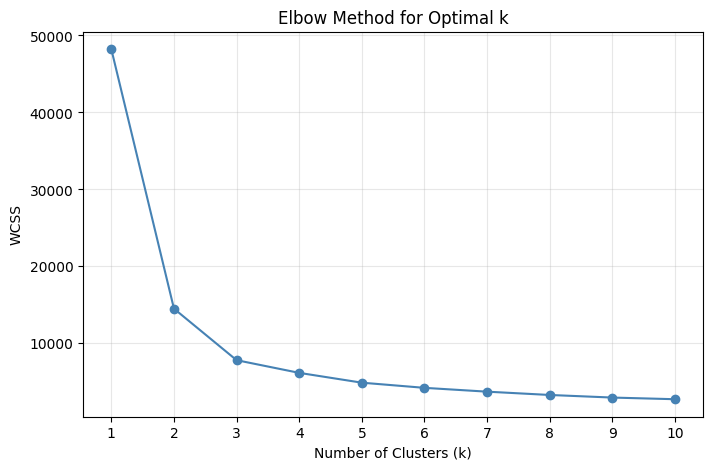

In [90]:
from sklearn.cluster import KMeans

# Calculate the Within-Cluster Sum of Squares (WCSS)
wcss = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(rfm_scaled)
    wcss.append(km.inertia_)

# Print the values so you can read them off
for k, w in zip(k_range, wcss):
    print(f"k = {k:2d}   WCSS = {w:,.1f}")

# Plot the elbow curve with the number of clusters on the x-axis and WCSS on the y-axis
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), wcss, marker="o", color="steelblue")
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

In [91]:
# Fit the K-Means model using the optimal number of clusters obtained after understanding the elblow plot
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(rfm_scaled)


# Add the assigned cluster labels to the Pandas DataFrame and convert back to PySpark if needed
rfm_pd["Cluster"] = cluster_labels.astype(int)

rfm = spark.createDataFrame(rfm_pd)

print("Cluster sizes:")
print(rfm_pd["Cluster"].value_counts().sort_index())

print("\nAverage RFM values per cluster (original scale):")
print(rfm_pd.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1))

rfm.show(5)

Cluster sizes:
Cluster
0    5349
1    3470
2    5329
3    1923
Name: count, dtype: int64

Average RFM values per cluster (original scale):
         Recency  Frequency  Monetary
Cluster                              
0          805.8        1.3      65.5
1          584.9      413.6   11599.2
2         1603.5        1.2      66.1
3          654.3       45.3    1514.6
+-----------------+-------+---------+------------------+-----------------+------------------+------------------+-------+
|Survey ResponseID|Recency|Frequency|          Monetary|      Recency_log|     Frequency_log|      Monetary_log|Cluster|
+-----------------+-------+---------+------------------+-----------------+------------------+------------------+-------+
|R_1jO4s7oht3pyKEc|    518|      564|13287.829999999949|6.251903883165888| 6.336825731146441| 9.494679111714499|      1|
|R_10TV1zyi4yCEEkl|    525|     1051|29788.359999999913| 6.26530121273771|6.9584483932976555|10.301906561757178|      1|
|R_1eWdieBjoYJXAYv|    606| 

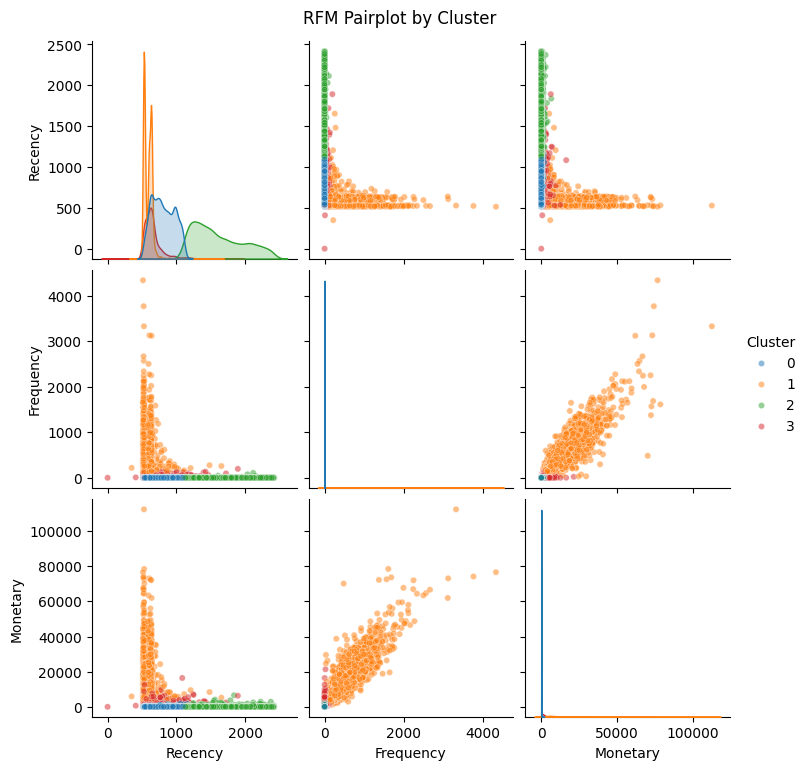

In [92]:
# Convert the full RFM dataset from PySpark DataFrame to Pandas DataFrame for visualisation
rfm_vis = rfm.toPandas()


# Generate a pairplot to visualise the relationships between the numeric RFM columns
plot_cols = ["Recency", "Frequency", "Monetary", "Cluster"]

g = sns.pairplot(
    rfm_vis[plot_cols],
    hue="Cluster",
    palette="tab10",
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 20}
)
g.fig.suptitle("RFM Pairplot by Cluster", y=1.02)
plt.show()

### Behavioral Trends Analysis <font color = red>[8 marks]</font> <br>

Perform RFM analysis to study the behavior of customers to tailor marketing strategies

In [93]:
# Import necessary PySpark functions for data processing
from pyspark.sql.functions import (
    col, lit, datediff, countDistinct, log1p,
    max as spark_max, sum as spark_sum
)
from sklearn.preprocessing import StandardScaler
# Group the dataset by 'Survey ResponseID' to calculate RFM (Recency, Frequency, Monetary) metrics

# Compute 'Recency' as the difference between the latest date and the most recent order date
# Compute 'Frequency' as the count of distinct product purchases (ASIN/ISBN)
# Compute 'Monetary' as the total spending sum for each customer
latest_date = merged_data.agg(spark_max("Order Date")).collect()[0][0]
rfm = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(
        # Recency: days between the latest date and the customer's most recent order
        datediff(lit(latest_date), spark_max("Order Date")).alias("Recency"),
        # Frequency: count of distinct products purchased (ASIN/ISBN)
        countDistinct("ASIN/ISBN (Product Code)").alias("Frequency"),
        # Monetary: total spending
        spark_sum("Revenue").alias("Monetary")
    )
    .filter((col("Frequency") > 0) & (col("Monetary") > 0))
)

# Rename columns if required and normlise the distributions
rfm = (
    rfm
    .withColumn("Recency_log", log1p(col("Recency")))
    .withColumn("Frequency_log", log1p(col("Frequency")))
    .withColumn("Monetary_log", log1p(col("Monetary")))
)

# Convert the processed RFM dataset back to Pandas for sklearn compatibility for clustering
rfm_pd = rfm.toPandas()

features = ["Recency_log", "Frequency_log", "Monetary_log"]
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_pd[features])

print(rfm_pd.shape)
print(rfm_pd[features].describe().round(2))

(16071, 7)
       Recency_log  Frequency_log  Monetary_log
count     16071.00       16071.00      16071.00
mean          6.81           2.16          5.07
std           0.45           2.15          2.59
min           0.00           0.69          0.01
25%           6.43           0.69          2.94
50%           6.70           0.69          4.04
75%           7.17           4.19          7.56
max           7.79           8.38         11.63


In [94]:
# Apply K-Means clustering
optimal_k = 4

# Fit the K-Means model and predict cluster labels for each customer
kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(rfm_scaled)


# Add the predicted cluster labels to the Pandas DataFrame
rfm_pd["Cluster"] = cluster_labels.astype(int)


# Convert the Pandas DataFrame back to a PySpark DataFrame
rfm = spark.createDataFrame(rfm_pd)

print("Cluster sizes:")
print(rfm_pd["Cluster"].value_counts().sort_index())

print("\nAverage RFM values per cluster (original scale):")
print(rfm_pd.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1))

rfm.show(5)

Cluster sizes:
Cluster
0    5324
1    3466
2    5355
3    1926
Name: count, dtype: int64

Average RFM values per cluster (original scale):
         Recency  Frequency  Monetary
Cluster                              
0         1604.0        1.2      66.0
1          584.9      413.9   11608.8
2          806.1        1.3      65.6
3          654.2       45.4    1519.0
+-----------------+-------+---------+------------------+-----------------+------------------+------------------+-------+
|Survey ResponseID|Recency|Frequency|          Monetary|      Recency_log|     Frequency_log|      Monetary_log|Cluster|
+-----------------+-------+---------+------------------+-----------------+------------------+------------------+-------+
|R_1jO4s7oht3pyKEc|    518|      564| 13287.82999999995|6.251903883165888| 6.336825731146441| 9.494679111714499|      1|
|R_10TV1zyi4yCEEkl|    525|     1051|29788.359999999906| 6.26530121273771|6.9584483932976555|10.301906561757178|      1|
|R_1eWdieBjoYJXAYv|    606| 

Analyse the Cluster Distribution by Income <font color = red>[2 marks]</font> <br>


Cluster                 0      1     2      3
Q-demos-income                               
Less than $25,000    15.0  382.0   8.0  280.0
$25,000 - $49,999    11.0  736.0  17.0  425.0
$50,000 - $74,999    12.0  727.0  10.0  314.0
$75,000 - $99,999     7.0  560.0  10.0  184.0
$100,000 - $149,999   6.0  614.0   7.0  163.0
$150,000 or more      3.0  389.0   3.0   68.0
Prefer not to say     3.0   41.0   3.0   29.0


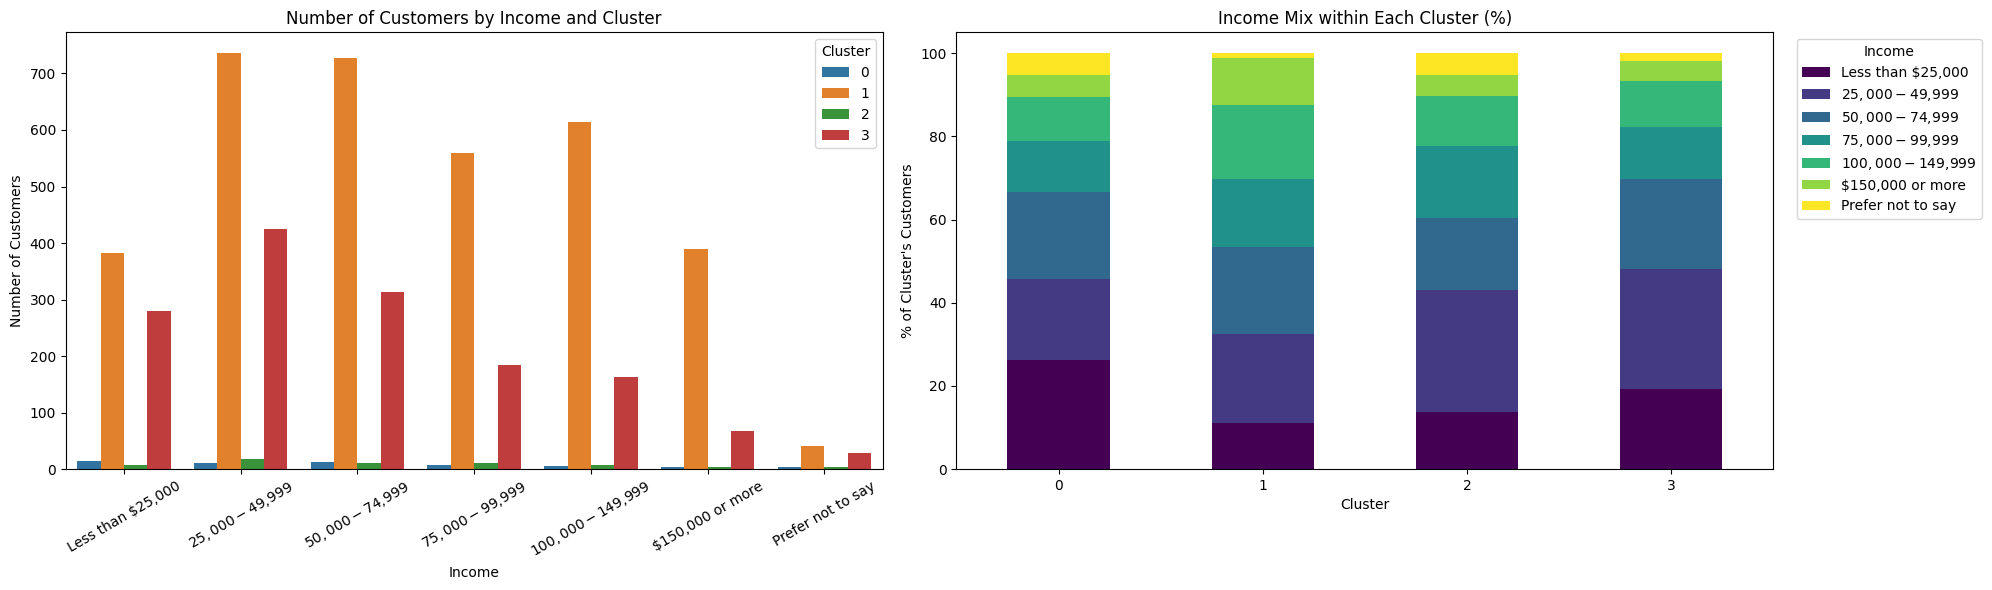

In [95]:
#Trend 1: Cluster Distribution by Income

# Import the necessary function for counting records in PySpark
from pyspark.sql.functions import count, col
import matplotlib.pyplot as plt
import seaborn as sns

# Join the RFM dataset with the survey dataset using a common key
rfm_income = rfm.join(
    survey.select("Survey ResponseID", "Q-demos-income"),
    on="Survey ResponseID",
    how="left"
)

# Aggregate data to count the number of customers per Cluster-Income group
cluster_income = (
    rfm_income
    .filter(col("Q-demos-income").isNotNull())
    .groupBy("Cluster", "Q-demos-income")
    .agg(count("*").alias("Num_Customers"))
)

# Convert the aggregated data from PySpark DataFrame to Pandas DataFrame for visualisation
ci_pd = cluster_income.toPandas()

income_order = [
    "Less than $25,000", "$25,000 - $49,999", "$50,000 - $74,999",
    "$75,000 - $99,999", "$100,000 - $149,999", "$150,000 or more", "Prefer not to say"
]
ci_pd = ci_pd[ci_pd["Q-demos-income"].isin(income_order)]
ci_table = ci_pd.pivot_table(index="Q-demos-income", columns="Cluster",
                             values="Num_Customers", fill_value=0).reindex(income_order).dropna(how="all")
print(ci_table)
ci_share = ci_table.div(ci_table.sum(axis=0), axis=1) * 100

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

sns.barplot(x="Q-demos-income", y="Num_Customers", hue="Cluster", data=ci_pd,
            order=income_order, palette="tab10", ax=axes[0])
axes[0].set_title("Number of Customers by Income and Cluster")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=30)

ci_share.T.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Income Mix within Each Cluster (%)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("% of Cluster's Customers")
axes[1].legend(title="Income", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Analyse the Average Spending by Cluster <font color = red>[2 marks]</font> <br>


   Cluster  Num_Customers  Avg_Recency_log  Avg_Frequency  Avg_Monetary_log  \
0        0           5324             7.36           1.17              3.29   
1        1           3466             6.37         413.95              9.10   
2        2           5355             6.67           1.27              3.55   
3        3           1926             6.46          45.44              7.02   

   Avg_Monetary_USD  
0             66.01  
1          11608.77  
2             65.60  
3           1519.01  


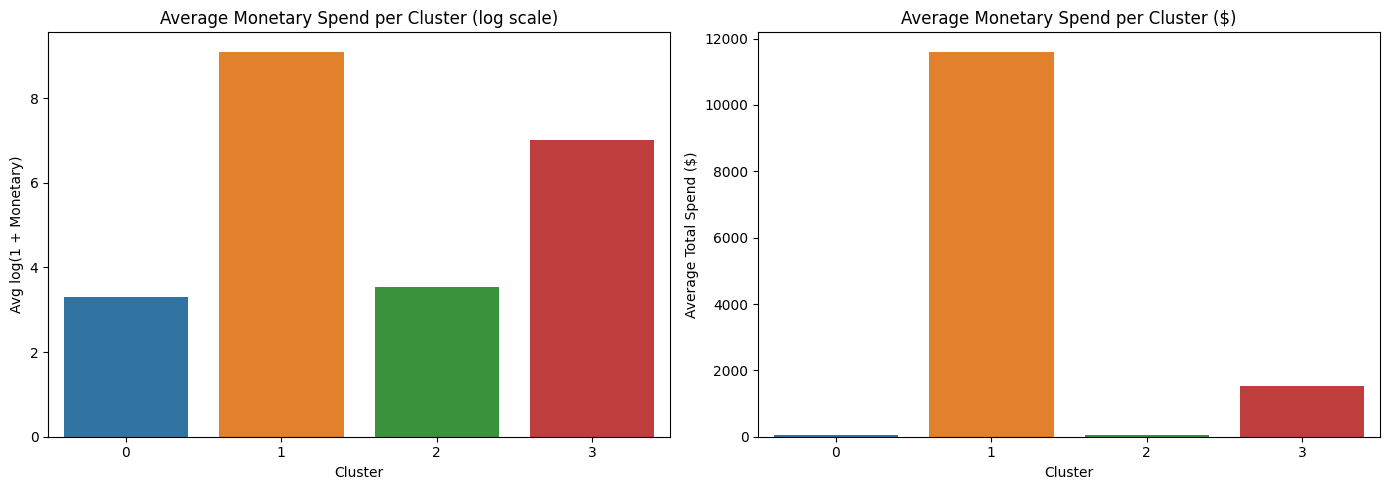

In [96]:
#Trend 2: Average Spending by Cluster

# Import the required function for calculating averages in PySpark
from pyspark.sql.functions import avg, count, col, round as spark_round
import matplotlib.pyplot as plt
import seaborn as sns

# Compute the average values of 'Recency_log', 'Frequency', and 'Monetary_log' for each customer cluster
cluster_summary = (
    rfm.groupBy("Cluster")
    .agg(
        count("*").alias("Num_Customers"),
        avg("Recency_log").alias("Avg_Recency_log"),
        avg("Frequency").alias("Avg_Frequency"),
        avg("Monetary_log").alias("Avg_Monetary_log"),
        avg("Monetary").alias("Avg_Monetary_USD")
    )
    .orderBy("Cluster")
)

# Convert the aggregated cluster summary from PySpark DataFrame to Pandas DataFrame for visualisation
cluster_pd = cluster_summary.toPandas()
print(cluster_pd.round(2))


# Generate a bar plot to visualise the average monetary spending per cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x="Cluster", y="Avg_Monetary_log", data=cluster_pd, palette="tab10", hue="Cluster",
            legend=False, ax=axes[0])
axes[0].set_title("Average Monetary Spend per Cluster (log scale)")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Avg log(1 + Monetary)")

sns.barplot(x="Cluster", y="Avg_Monetary_USD", data=cluster_pd, palette="tab10", hue="Cluster",
            legend=False, ax=axes[1])
axes[1].set_title("Average Monetary Spend per Cluster ($)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average Total Spend ($)")

plt.tight_layout()
plt.show()

Analyse the Purchase Frequency vs. Recency <font color = red>[2 marks]</font> <br>


Correlation (log Recency vs log Frequency): -0.627


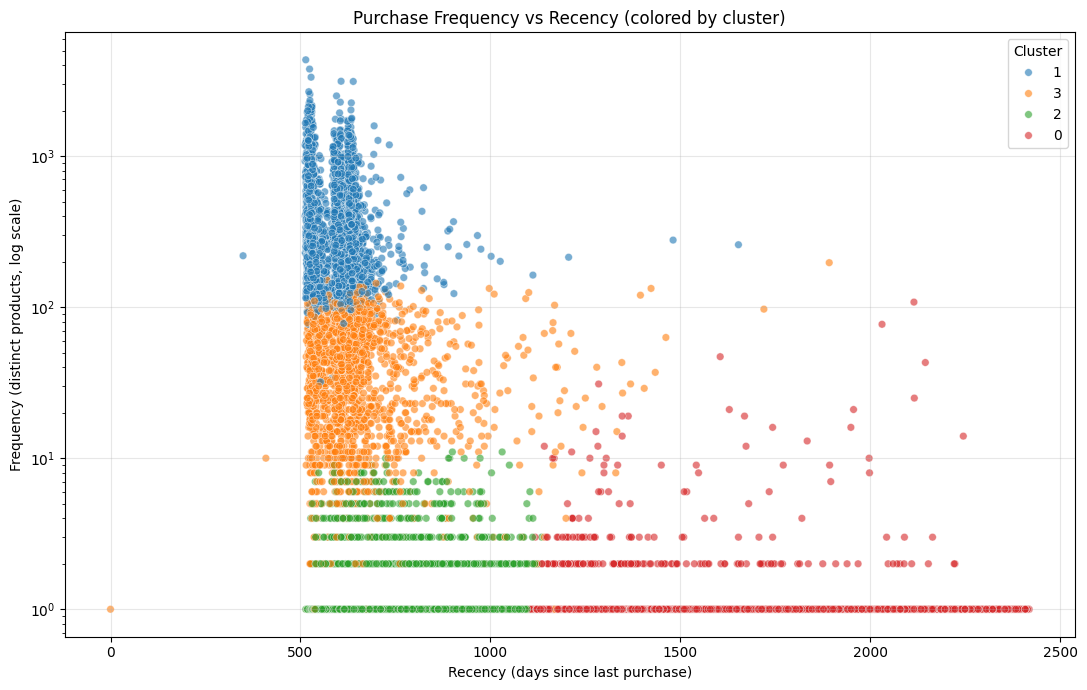

In [97]:
#Trend 3: Purchase Frequency vs. Recency

# Convert the RFM dataset from PySpark DataFrame to Pandas DataFrame for visualisation
rfm_trend = rfm.toPandas()
rfm_trend["Cluster"] = rfm_trend["Cluster"].astype(str)   # discrete colors

# Correlation (on log scale, where the skew is tamed)
corr_val = rfm_trend["Recency_log"].corr(rfm_trend["Frequency_log"])
print(f"Correlation (log Recency vs log Frequency): {corr_val:.3f}")

# Generate a scatter plot to analyse the relationship between Purchase Frequency and Recency
plt.figure(figsize=(11, 7))
sns.scatterplot(
    x="Recency", y="Frequency", hue="Cluster", data=rfm_trend,
    palette="tab10", alpha=0.6, s=30
)
plt.yscale("log")
plt.title("Purchase Frequency vs Recency (colored by cluster)")
plt.xlabel("Recency (days since last purchase)")
plt.ylabel("Frequency (distinct products, log scale)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Analyse the top categories by clusters <font color = red>[2 marks]</font> <br>


    Cluster  Rank                             Category  Total_Spend
0         0     1                        GeForce MX150      6596.86
1         0     2                            16GB DDR4      4549.97
2         0     3   Black (Previous Generation - 7th)"      4532.15
3         0     4                             8GB DDR4      4030.32
4         0     5                              4GB RAM      3606.84
5         1     1                            ABIS_BOOK   1239579.67
6         1     2                            GIFT_CARD    782306.01
7         1     3                             PET_FOOD    747648.39
8         1     4               NUTRITIONAL_SUPPLEMENT    596716.99
9         1     5                                SHOES    545918.01
10        2     1                               Black"      3674.57
11        2     2                               White"      3020.33
12        2     3                        Ad-Supported"      2095.59
13        2     4                            32G

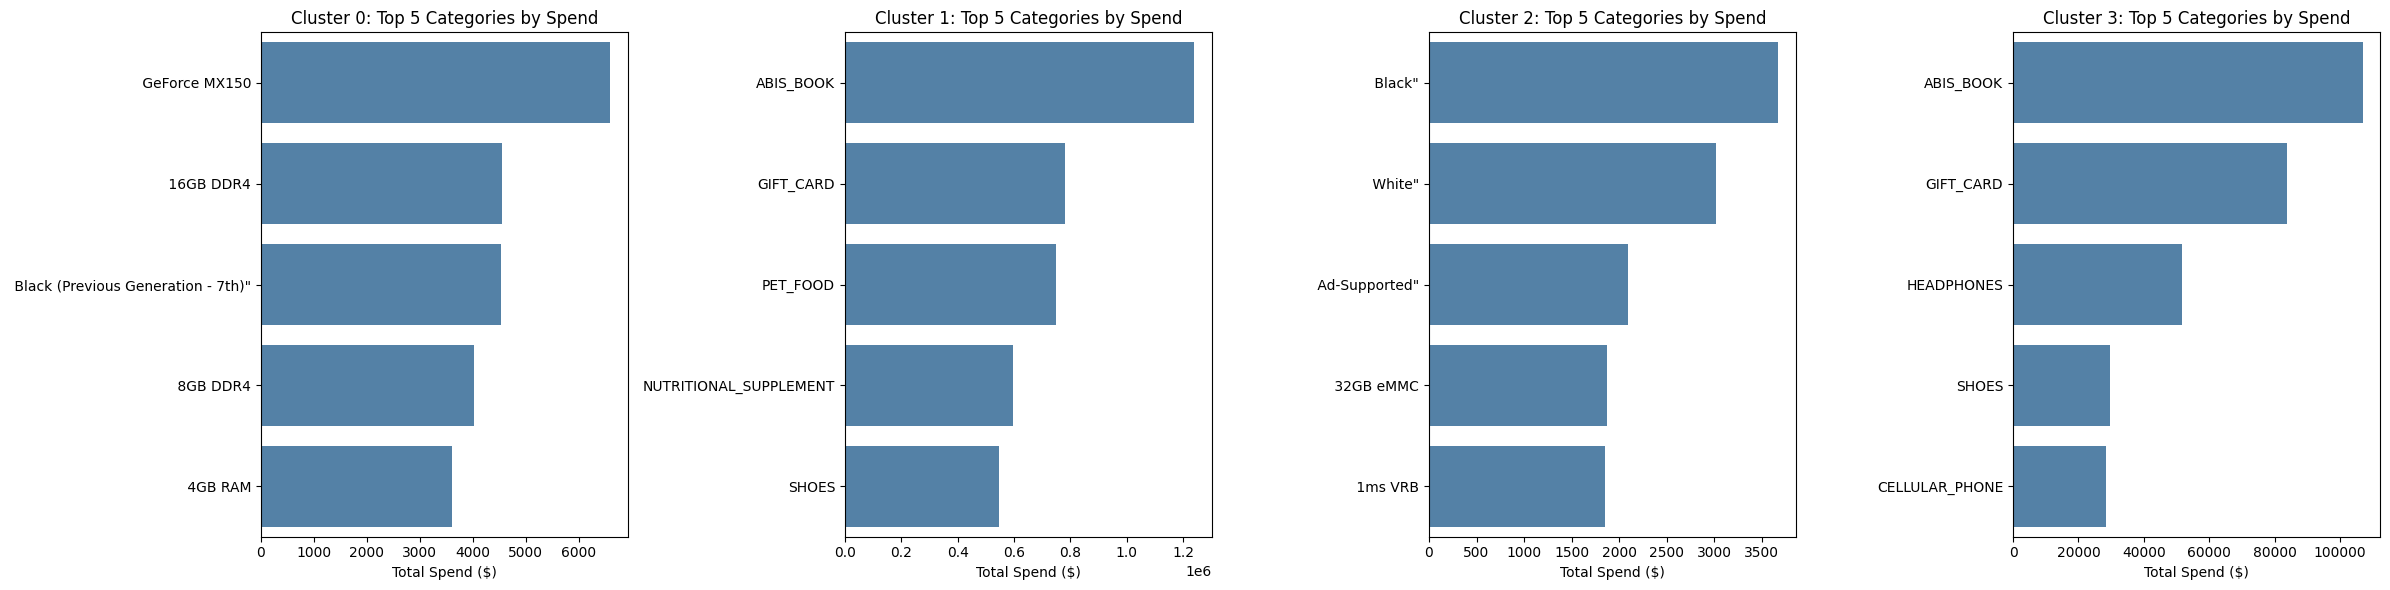

In [98]:
#Trend 4: Top Categories by Cluster

# Import the necessary function to calculate the sum in PySpark
from pyspark.sql.functions import sum as spark_sum, col, row_number
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import seaborn as sns

# Join the merged dataset with the RFM dataset to associate each customer with their respective cluster
cluster_sales = (
    merged_data
    .filter(col("Category") != "Unknown")
    .join(rfm.select("Survey ResponseID", "Cluster"), on="Survey ResponseID", how="inner")
)

# Group the filtered data by 'Category' and compute the total spending in each category
cat_spend = (
    cluster_sales
    .groupBy("Cluster", "Category")
    .agg(spark_sum("Revenue").alias("Total_Spend"))
)

# Order the categories by total spending in descending order and select the top 5 highest spending categories
w = Window.partitionBy("Cluster").orderBy(col("Total_Spend").desc())
top_cats = (
    cat_spend
    .withColumn("Rank", row_number().over(w))
    .filter(col("Rank") <= 5)
    .orderBy("Cluster", "Rank")
)

# Convert the top categories dataset from PySpark DataFrame to Pandas DataFrame for visualisation
top_cats_pd = top_cats.toPandas()
print(top_cats_pd[["Cluster", "Rank", "Category", "Total_Spend"]])

# Plot the cluster
clusters = sorted(top_cats_pd["Cluster"].unique())
fig, axes = plt.subplots(1, len(clusters), figsize=(6 * len(clusters), 6), sharex=False)
if len(clusters) == 1:
    axes = [axes]

for ax, c in zip(axes, clusters):
    data = top_cats_pd[top_cats_pd["Cluster"] == c]
    sns.barplot(y="Category", x="Total_Spend", data=data, ax=ax, color="steelblue")
    ax.set_title(f"Cluster {c}: Top 5 Categories by Spend")
    ax.set_xlabel("Total Spend ($)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

## 4.2 Insights <font color = red>[35 marks]</font> <br>


### 4.2.1 When to schedule effective promotions. <font color = red>[3 marks]</font> <br>

Compare sales across weekdays to schedule effective promotions

   Day  Total_Sales  Num_Days  Avg_Sales_per_Day
0  Sun   6118267.61       272       22493.630919
1  Mon   6823410.49       274       24902.957993
2  Tue   6650368.34       274       24271.417299
3  Wed   6375856.48       273       23354.785641
4  Thu   6036843.81       274       22032.276679
5  Fri   6164346.11       274       22497.613540
6  Sat   5697536.42       272       20946.825074
Strongest day: Mon | Weakest day: Sat


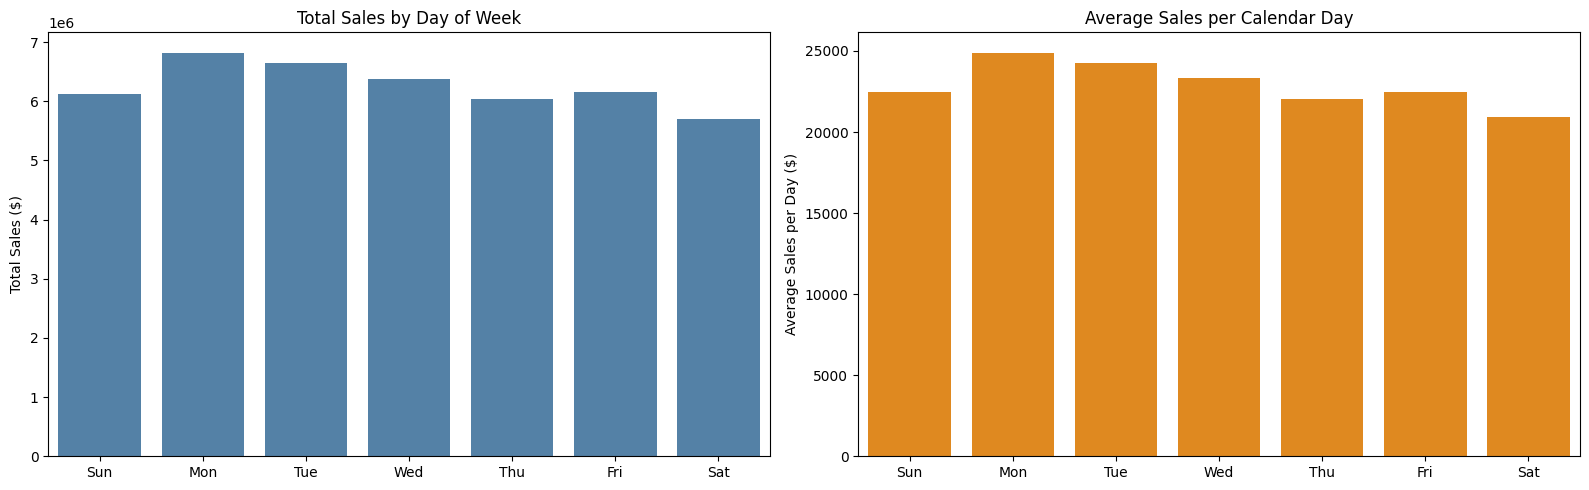

In [99]:
#Compare sales across weekdays to schedule effective promotions

from pyspark.sql.functions import dayofweek

# Extract day of the week (1 = Sunday, 7 = Saturday)
weekday_df = merged_data.withColumn("DayOfWeek", dayofweek(col("Order Date")))

# Group by weekday and sum total sales
weekday_sales = (
    weekday_df.groupBy("DayOfWeek")
    .agg(
        spark_sum("Revenue").alias("Total_Sales"),
        countDistinct("Order Date").alias("Num_Days")
    )
    .withColumn("Avg_Sales_per_Day", col("Total_Sales") / col("Num_Days"))
    .orderBy("DayOfWeek")
)

# Convert to Pandas for visualisation
weekday_pd = weekday_sales.toPandas()
day_names = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
weekday_pd["Day"] = weekday_pd["DayOfWeek"].map(day_names)
print(weekday_pd[["Day", "Total_Sales", "Num_Days", "Avg_Sales_per_Day"]])

best = weekday_pd.loc[weekday_pd["Avg_Sales_per_Day"].idxmax(), "Day"]
worst = weekday_pd.loc[weekday_pd["Avg_Sales_per_Day"].idxmin(), "Day"]
print(f"Strongest day: {best} | Weakest day: {worst}")

# Plot sales by weekday
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x="Day", y="Total_Sales", data=weekday_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Total Sales by Day of Week")
axes[0].set_ylabel("Total Sales ($)")

sns.barplot(x="Day", y="Avg_Sales_per_Day", data=weekday_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Average Sales per Calendar Day")
axes[1].set_ylabel("Average Sales per Day ($)")

for ax in axes:
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

### 4.2.2 Top-selling Products <font color = red>[2 marks]</font> <br>

Identify top-selling products by considering revenue and engagement metrics

                                         Short_Title  Total_Revenue  \
0                Amazon.com Gift Card Balance Reload      226175.22   
1                              Amazon.com eGift Card      215947.95   
2                                      Amazon Reload      117078.49   
3  Apple AirPods (2nd Generation) Wireless Earbud...       39276.84   
4  Google Play gift code - give the gift of games...       35219.92   
5  Apple Gift Card - App Store, iTunes, iPhone, i...       28382.79   
6                              PlayStation 5 Console       26913.35   
7                                  Apple AirPods Pro       25942.00   
8  Nintendo Switch with Neon Blue and Neon Red Jo...       24276.47   
9  Amazon.com Gift Card in a Holiday Gift Box (Va...       20725.00   

   Num_Purchases  Unique_Buyers  Units_Sold  
0           8282           1157        8282  
1           4682           1347        5179  
2           4876            873        4876  
3            289            221   

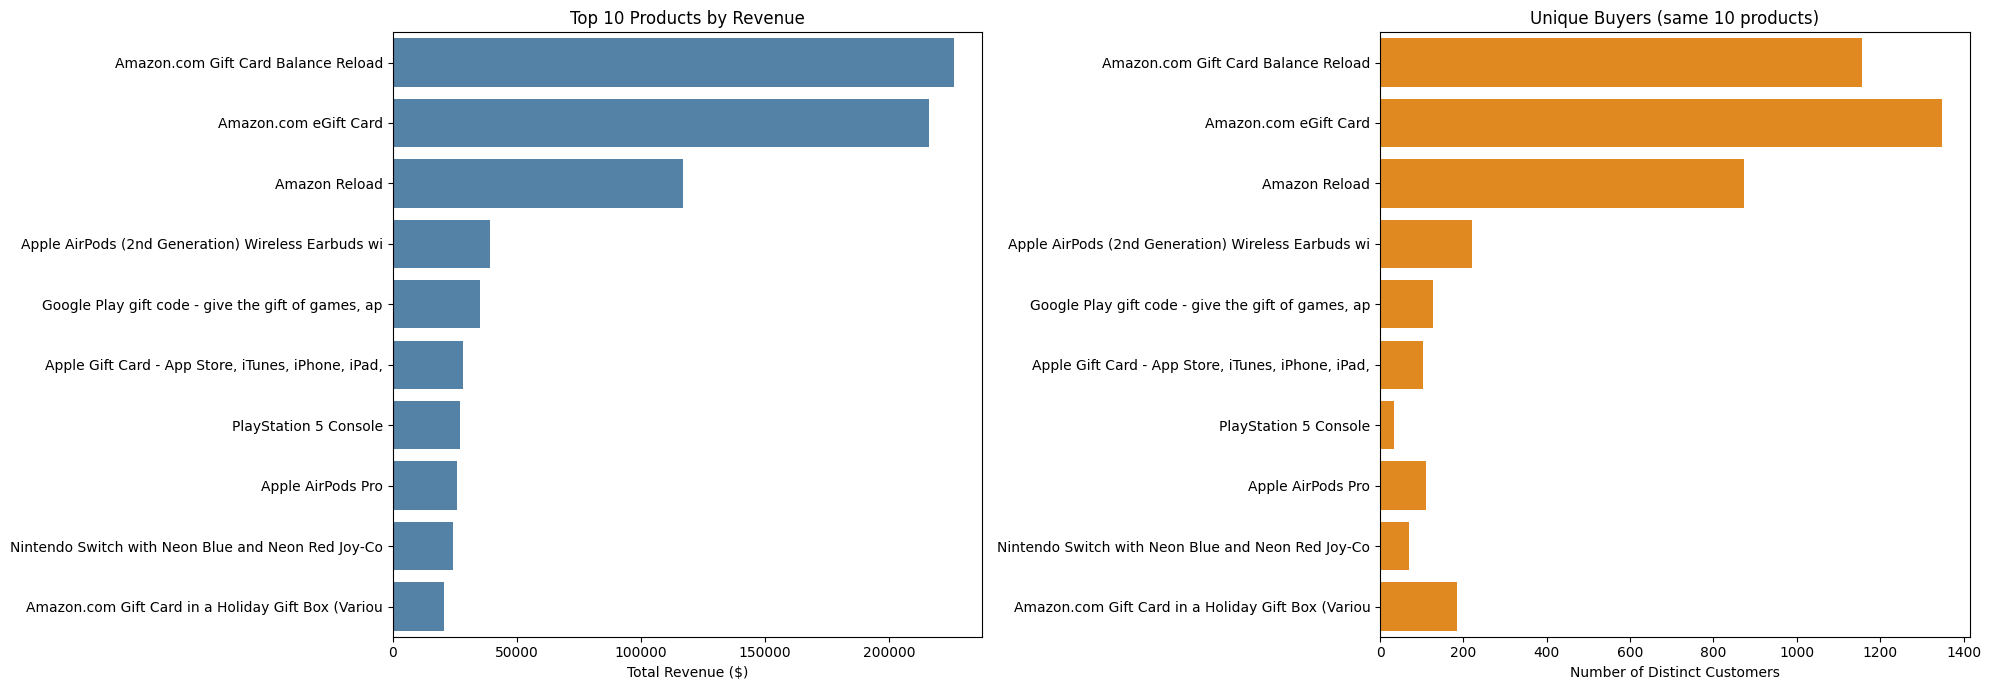

In [100]:
#Identify top-selling products using revenue and engagement metrics

# Group by product and sum revenue
product_perf = (
    merged_data
    .filter(col("Title") != "Unknown")
    .groupBy("Title")
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        count("*").alias("Num_Purchases"),
        countDistinct("Survey ResponseID").alias("Unique_Buyers"),
        spark_sum("Quantity").alias("Units_Sold")
    )
)

# Get top 10 products by revenue
top10_rev = product_perf.orderBy(col("Total_Revenue").desc()).limit(10)

# Convert to Pandas for visualisation
top10_pd = top10_rev.toPandas()
top10_pd["Short_Title"] = top10_pd["Title"].str[:50]
print(top10_pd[["Short_Title", "Total_Revenue", "Num_Purchases", "Unique_Buyers", "Units_Sold"]])

# Plot top products by revenue
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

sns.barplot(y="Short_Title", x="Total_Revenue", data=top10_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Products by Revenue")
axes[0].set_xlabel("Total Revenue ($)")
axes[0].set_ylabel("")

sns.barplot(y="Short_Title", x="Unique_Buyers", data=top10_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Unique Buyers (same 10 products)")
axes[1].set_xlabel("Number of Distinct Customers")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2.3 State-wise revenue Distribution <font color = red>[5 marks]</font> <br>

Assess state-wise revenue to focus on high-growth areas

Years in data: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Growth measured from 2019 to 2022
Year                       2019      2022  Growth_%
Shipping Address State                             
HI                      17223.9   44588.8     158.9
AK                       5645.0   14485.3     156.6
VT                       7775.3   19368.8     149.1
SD                       8102.1   18051.7     122.8
NH                      34528.9   74180.5     114.8
NV                      60468.6  128736.5     112.9
UT                      45936.5   90999.9      98.1
ID                      20412.8   40271.6      97.3
RI                      16881.8   33199.9      96.7
DE                      25183.8   49341.3      95.9


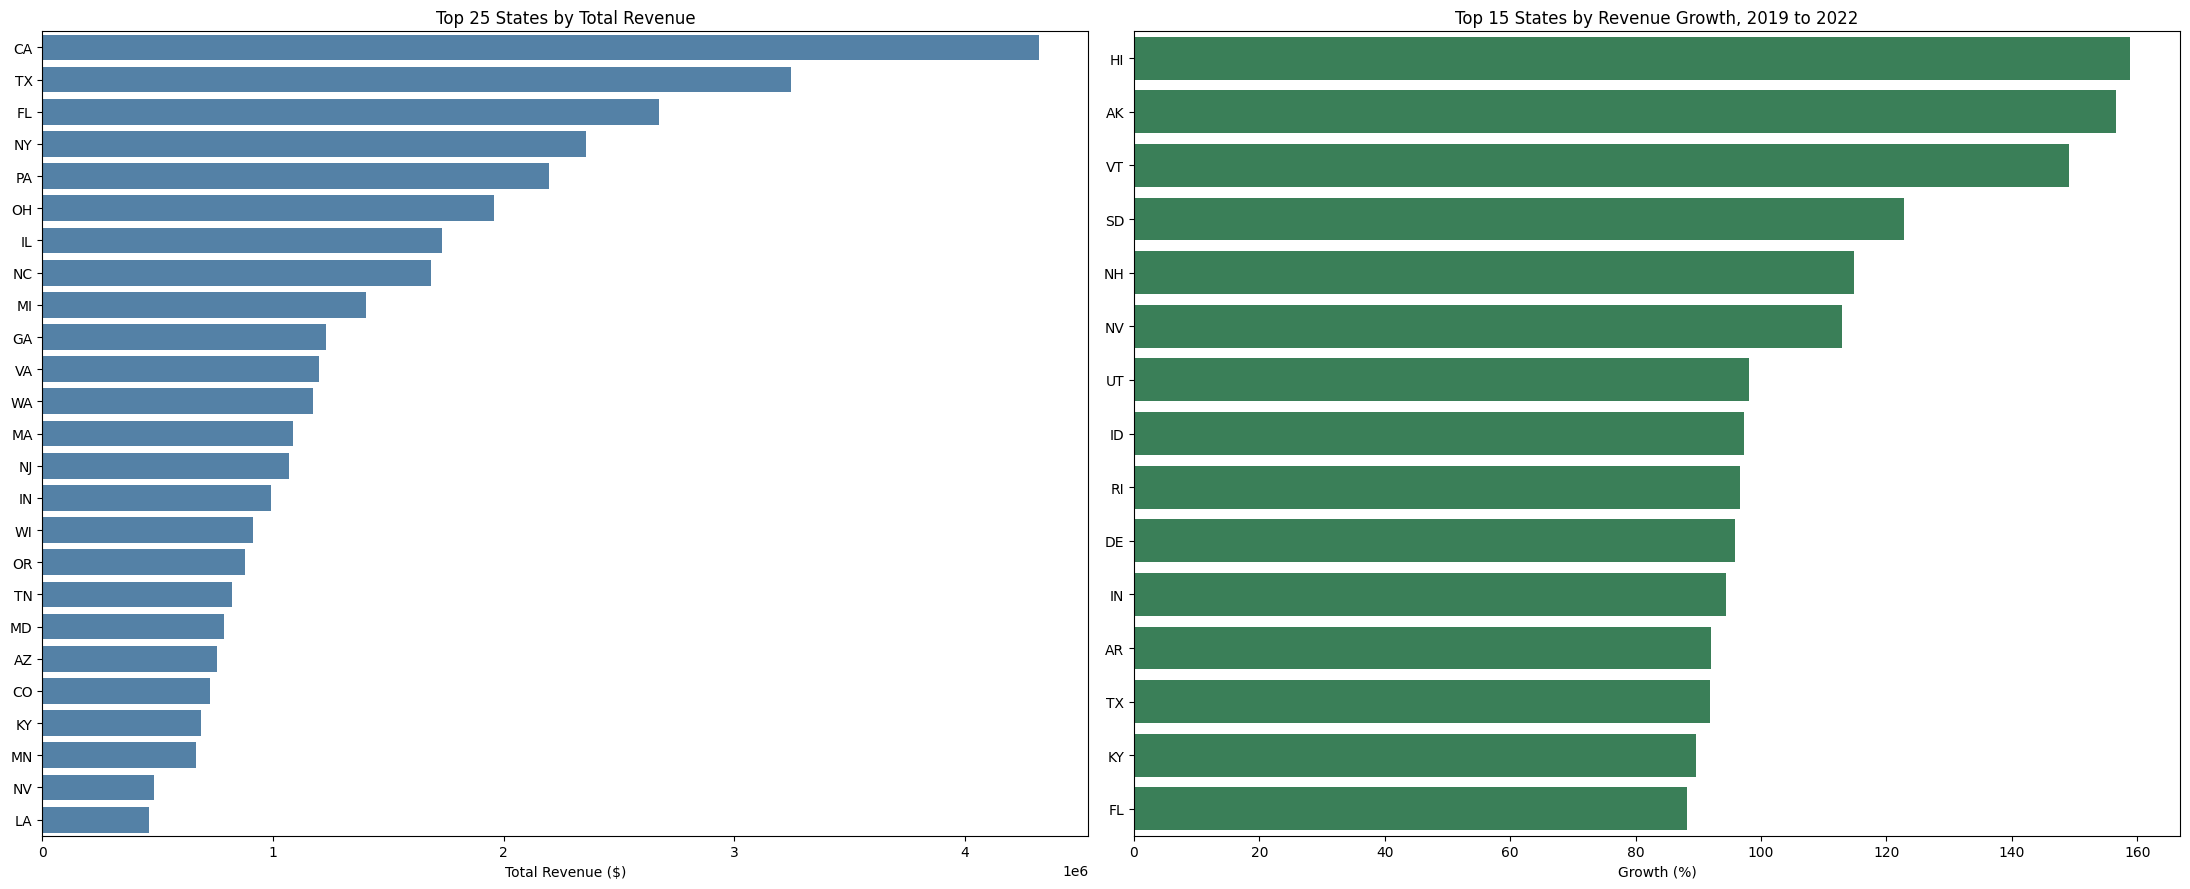

In [101]:
#Assess state-wise revenue to focus on high-growth areas
state_col = "Shipping Address State"

state_df = (
    merged_data
    .filter(col(state_col) != "Unknown")
    .withColumn("Year", year(col("Order Date")))
)
# Group by state and sum revenue
state_rev = (
    state_df.groupBy(state_col)
    .agg(spark_sum("Revenue").alias("Total_Revenue"))
    .orderBy(col("Total_Revenue").desc())
)
state_year = state_df.groupBy(state_col, "Year").agg(spark_sum("Revenue").alias("Revenue"))


# Convert to Pandas for visualisation
state_pd = state_rev.toPandas()
sy_pd = state_year.toPandas()

years_available = sorted(sy_pd["Year"].unique())
print("Years in data:", years_available)
first_year, last_year = years_available[1], years_available[-2]   # skip the edge years
print(f"Growth measured from {first_year} to {last_year}")

pivot = sy_pd.pivot_table(index=state_col, columns="Year", values="Revenue", fill_value=0)
growth = pivot[[first_year, last_year]].copy()
growth = growth[growth[first_year] >= 5000]    # ignore tiny bases, they give noisy % growth
growth["Growth_%"] = (growth[last_year] - growth[first_year]) / growth[first_year] * 100
growth = growth.sort_values("Growth_%", ascending=False)
print(growth.head(10).round(1))


# Plot revenue by state
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

top_states = state_pd.head(25)
sns.barplot(y=state_col, x="Total_Revenue", data=top_states, ax=axes[0], color="steelblue")
axes[0].set_title("Top 25 States by Total Revenue")
axes[0].set_xlabel("Total Revenue ($)")
axes[0].set_ylabel("")

top_growth = growth.head(15).reset_index()
sns.barplot(y=state_col, x="Growth_%", data=top_growth, ax=axes[1], color="seagreen")
axes[1].set_title(f"Top 15 States by Revenue Growth, {first_year} to {last_year}")
axes[1].set_xlabel("Growth (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2.4 Repeat Purchase Behavior <font color = red>[5 marks]</font> <br>

Examine repeat purchase behavior to enhance retention initiatives.

Total customers: 16,071
Repeat (more than 1 line item): 8,703 (54.2%)
Repeat (more than 1 order day): 8,669 (53.9%)
+-----------------+---------------+----------+
|Survey ResponseID|Total_Purchases|Order_Days|
+-----------------+---------------+----------+
|R_8CXcySQawXPuJwJ|           5258|       904|
|R_24csoaO569P4Yzz|           4675|      1168|
|R_2EglJpTWGEiwQYa|           4185|      1258|
|R_1QtQEfi1VAWgRM0|           3825|       861|
|R_3e5g4lvddcnjkoZ|           3815|       963|
|R_1PUcgnVG2i0EBz4|           3339|       644|
|R_32UZncFA03IrQwQ|           2931|       873|
|R_1rwrLVr6jBONnIg|           2923|       847|
|R_3R4b0PxgHJiXxVD|           2875|      1105|
|R_bJI8lmXMZWL6oql|           2856|       850|
+-----------------+---------------+----------+
only showing top 10 rows
Band
1        7402
2-5      2778
6-20     1159
21-50     972
50+      3760
Name: count, dtype: int64


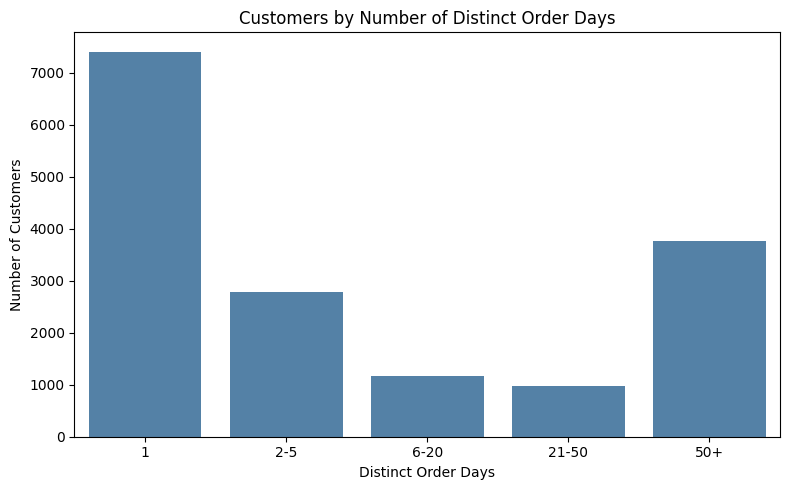

In [102]:
#Examine repeat purchase behavior to enhance retention initiatives

from pyspark.sql.functions import count, col

# Count total purchases per customer
customer_purchases = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(
        count("*").alias("Total_Purchases"),
        countDistinct("Order Date").alias("Order_Days")
    )
)

# Filter for repeat customers (those with more than one purchase)
repeat_customers = customer_purchases.filter(col("Total_Purchases") > 1)
repeat_by_day = customer_purchases.filter(col("Order_Days") > 1)

total_customers = customer_purchases.count()
n_repeat = repeat_customers.count()
n_repeat_day = repeat_by_day.count()
print(f"Total customers: {total_customers:,}")
print(f"Repeat (more than 1 line item): {n_repeat:,} ({n_repeat / total_customers:.1%})")
print(f"Repeat (more than 1 order day): {n_repeat_day:,} ({n_repeat_day / total_customers:.1%})")

# Show sample data
repeat_customers.orderBy(col("Total_Purchases").desc()).show(10)

bands = customer_purchases.toPandas()
bands["Band"] = bands["Order_Days"].apply(
    lambda d: "1" if d == 1 else "2-5" if d <= 5 else "6-20" if d <= 20 else "21-50" if d <= 50 else "50+"
)
band_counts = bands["Band"].value_counts().reindex(["1", "2-5", "6-20", "21-50", "50+"]).fillna(0)
print(band_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=band_counts.index, y=band_counts.values, color="steelblue")
plt.title("Customers by Number of Distinct Order Days")
plt.xlabel("Distinct Order Days")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 4.2.5 Flagging Potential Fraud <font color = red>[5 marks]</font> <br>

Identify irregular transaction patterns to flag potential fraud.

Mean transaction value: $23.85
Std dev: $49.28
Threshold (mean + 3 * std): $171.70
Flagged transactions: 20,437 (1.111% of all transactions)
+-----------------+----------+----------------------------------------+-----------------------------------+-----------------------+--------+-------+
|Survey ResponseID|Order Date|                                   Title|                           Category|Purchase Price Per Unit|Quantity|Revenue|
+-----------------+----------+----------------------------------------+-----------------------------------+-----------------------+--------+-------+
|R_3e8qukcDiaT0D0g|2020-02-16|LaCie 12big Thunderbolt 3 96TB STFJ96...|          COMPUTER_DRIVE_OR_STORAGE|                6398.95|       1|6398.95|
|R_3lMSxgNkhRq4147|2022-06-26|Weize 12V 200Ah LiFePO4 Lithium Batte...|                       AUTO_BATTERY|                 759.99|       8|6079.92|
|            Metro|2021-03-01|"Samsung Galaxy Z Flip (256GB, 8GB) 6...| AT&T Unlocked GSM 4G LTE (T-Mobile|       

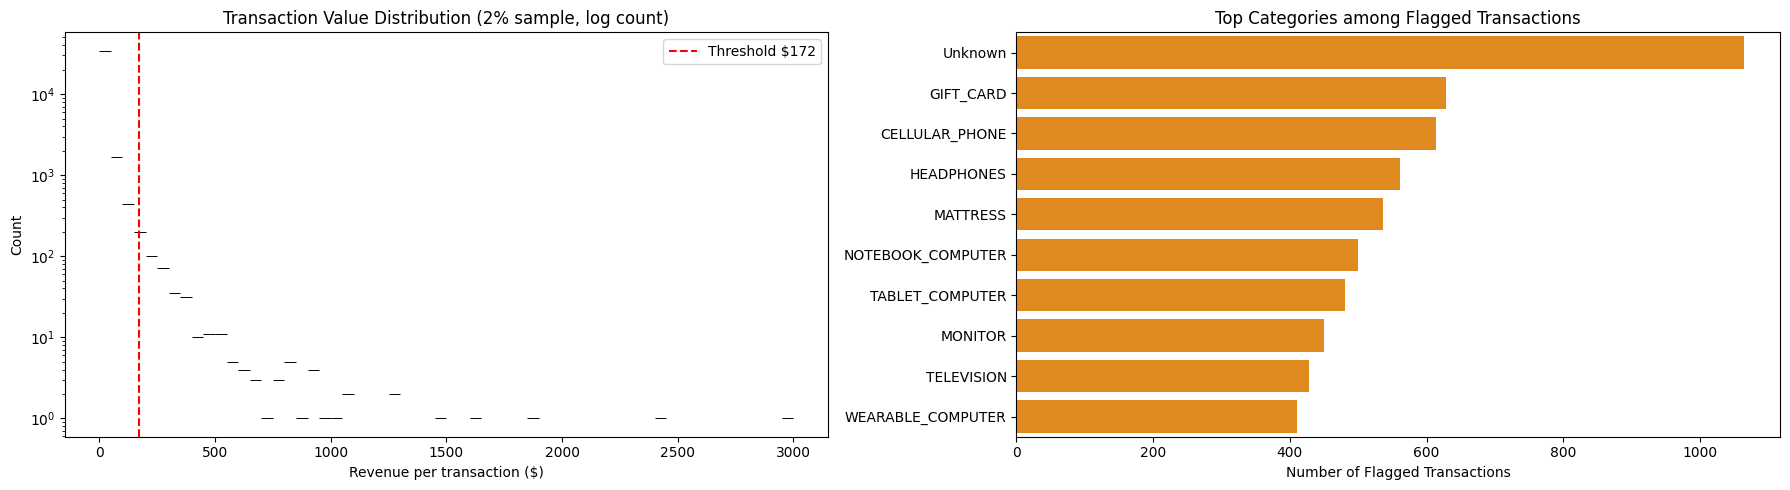

In [103]:
#Identify irregular transaction patterns to flag potential fraud

from pyspark.sql.functions import col, avg, stddev

# Calculate the threshold for unusually high spending
# Consider spending to be unusually high if the total spent is greater than the mean + 3 * std dev
stats = merged_data.agg(avg("Revenue").alias("mean"), stddev("Revenue").alias("std")).collect()[0]
mean_rev, std_rev = stats["mean"], stats["std"]
threshold = mean_rev + 3 * std_rev
print(f"Mean transaction value: ${mean_rev:,.2f}")
print(f"Std dev: ${std_rev:,.2f}")
print(f"Threshold (mean + 3 * std): ${threshold:,.2f}")


# Filter transactions that exceed the threshold
suspicious = merged_data.filter(col("Revenue") > threshold)
n_susp = suspicious.count()
n_total = merged_data.count()
print(f"Flagged transactions: {n_susp:,} ({n_susp / n_total:.3%} of all transactions)")


# Show suspicious transactions
(suspicious
    .select("Survey ResponseID", "Order Date", "Title", "Category",
            "Purchase Price Per Unit", "Quantity", "Revenue")
    .orderBy(col("Revenue").desc())
    .show(15, truncate=40))

cust_spend = (
    merged_data
    .filter(col("Survey ResponseID") != "Unknown")
    .groupBy("Survey ResponseID")
    .agg(spark_sum("Revenue").alias("Total_Spend"), count("*").alias("Num_Items"))
)
cs = cust_spend.agg(avg("Total_Spend").alias("m"), stddev("Total_Spend").alias("s")).collect()[0]
cust_threshold = cs["m"] + 3 * cs["s"]
flagged_customers = cust_spend.filter(col("Total_Spend") > cust_threshold)
print(f"\nCustomer spend threshold: ${cust_threshold:,.2f}")
print(f"Flagged customers: {flagged_customers.count()}")
flagged_customers.orderBy(col("Total_Spend").desc()).show(10)

susp_cat_pd = (
    suspicious.groupBy("Category").count()
    .orderBy(col("count").desc()).limit(10).toPandas()
)

#plot
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sample_pd = merged_data.select("Revenue").sample(fraction=0.02, seed=42).toPandas()
sns.histplot(sample_pd["Revenue"], bins=60, log_scale=(False, True), ax=axes[0], color="steelblue")
axes[0].axvline(threshold, color="red", linestyle="--", label=f"Threshold ${threshold:,.0f}")
axes[0].set_title("Transaction Value Distribution (2% sample, log count)")
axes[0].set_xlabel("Revenue per transaction ($)")
axes[0].legend()

sns.barplot(y="Category", x="count", data=susp_cat_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Top Categories among Flagged Transactions")
axes[1].set_xlabel("Number of Flagged Transactions")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2.6 Demand Variations across product categories <font color = red>[5 marks]</font> <br>

Perform inventory management by monitoring demand variations across product categories.

Most volatile categories (CV of monthly revenue):
Category
TELEVISION           0.97
TOY_FIGURE           0.75
TABLET_COMPUTER      0.65
NOTEBOOK_COMPUTER    0.65
DRESS                0.65
CELLULAR_PHONE       0.64
TOYS_AND_GAMES       0.63
CHAIR                0.61
MEDICATION           0.52
GIFT_CARD            0.51
dtype: float64

Most stable categories:
Category
SKIN_MOISTURIZER          0.37
ELECTRONIC_CABLE          0.37
SHOES                     0.37
CELLULAR_PHONE_CASE       0.36
NUTRITIONAL_SUPPLEMENT    0.35
dtype: float64


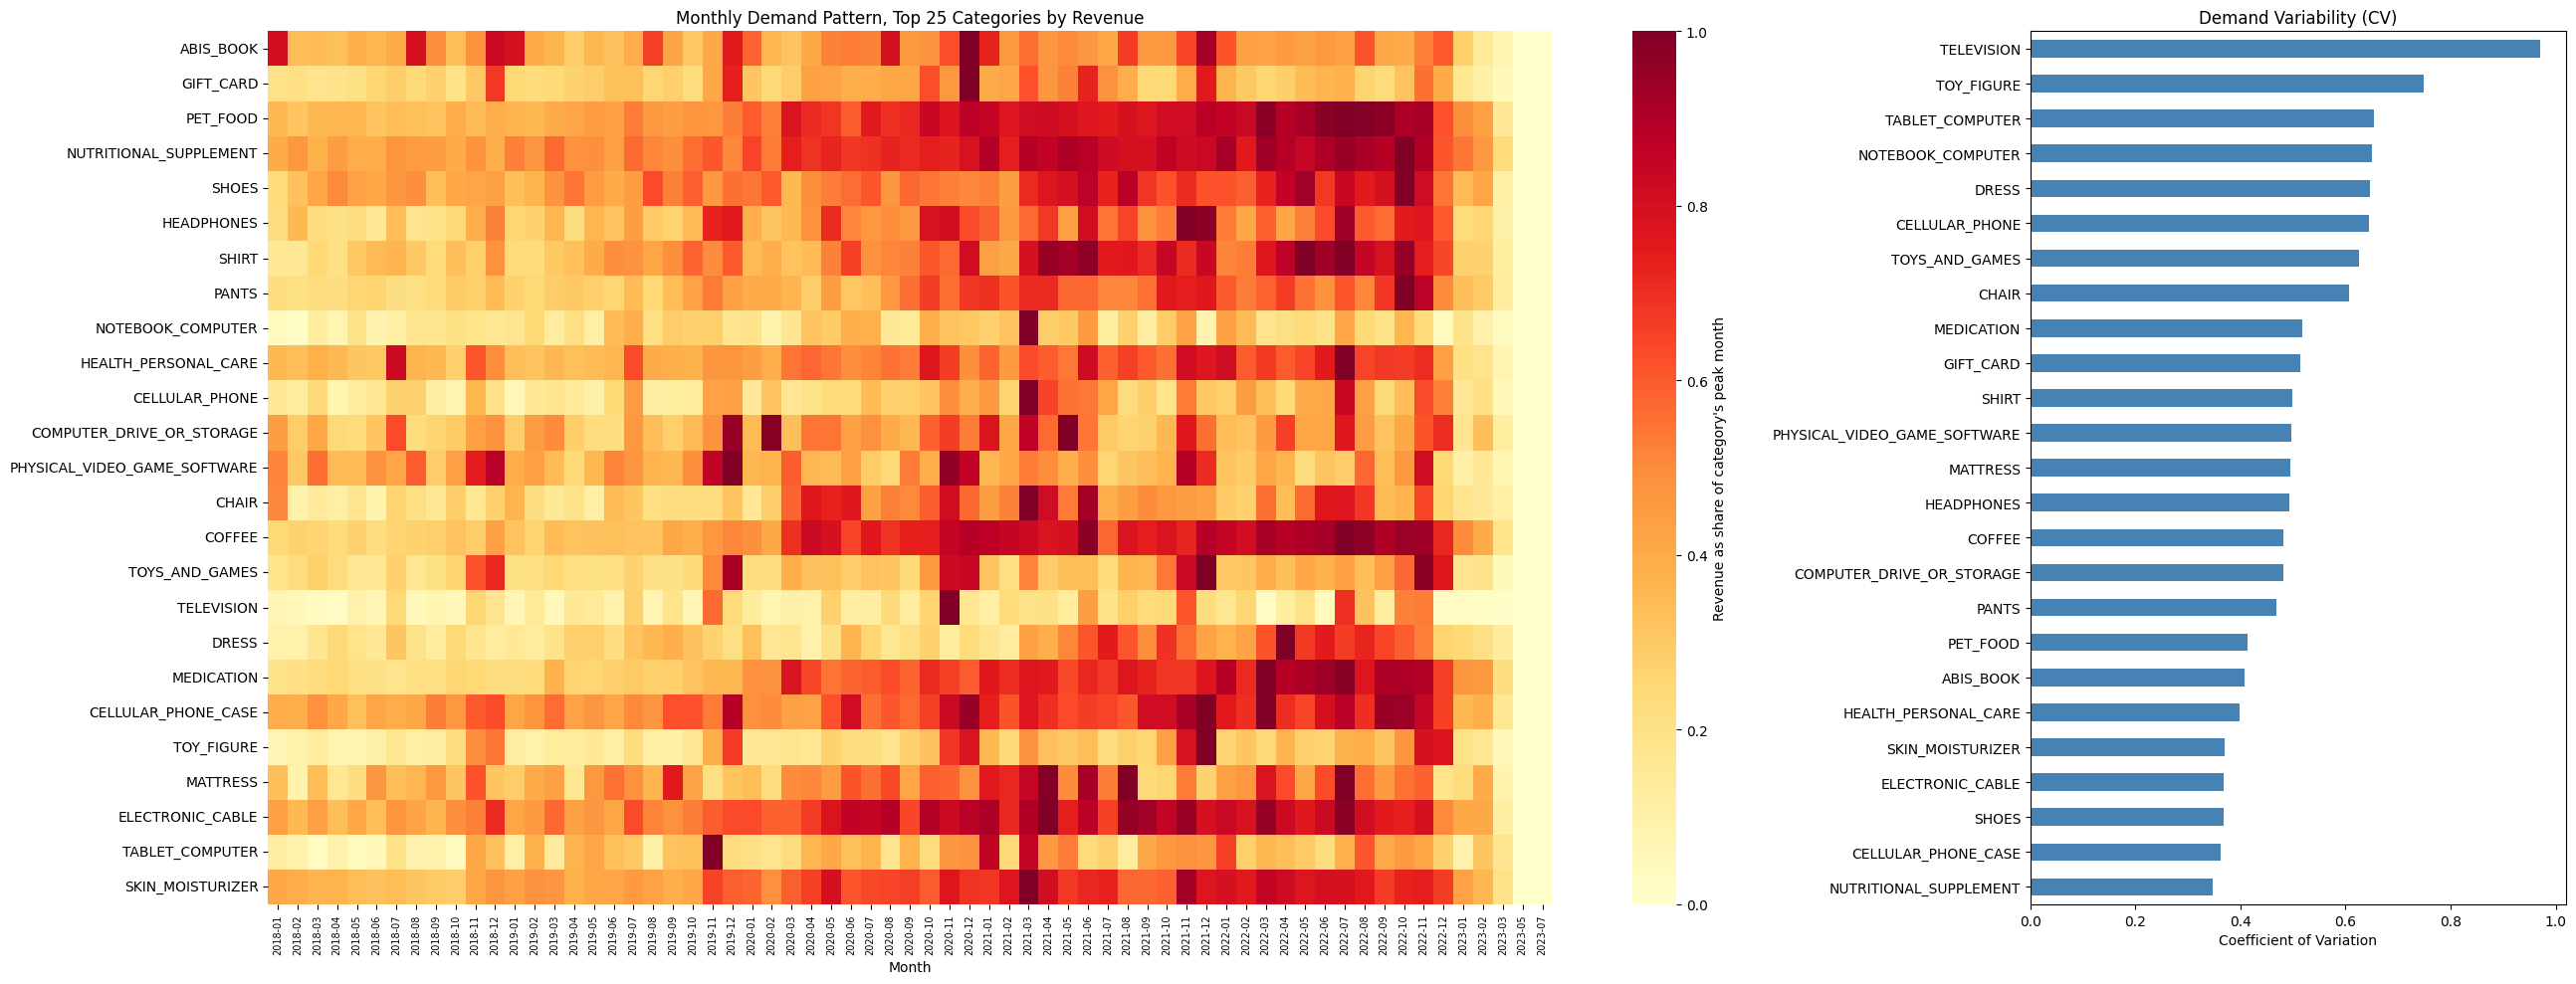

In [104]:
#Monitor demand variations across product categories (Top 25) for inventory management

from pyspark.sql.functions import col, sum
import matplotlib.pyplot as plt
import seaborn as sns

# Group by category and month, summing total revenue
category_trends = (
    merged_data
    .filter(col("Category") != "Unknown")
    .withColumn("Year_Month", date_format(col("Order Date"), "yyyy-MM"))
    .groupBy("Category", "Year_Month")
    .agg(spark_sum("Revenue").alias("Monthly_Revenue"))
)

# Compute total revenue per category
category_totals = category_trends.groupBy("Category").agg(spark_sum("Monthly_Revenue").alias("Total_Revenue"))

# Get the top 25 categories by total revenue
top25 = category_totals.orderBy(col("Total_Revenue").desc()).limit(25)

# Filter category_trends to include only top 25 categories
category_trends_top = category_trends.join(top25.select("Category"), on="Category", how="inner")

# Convert to Pandas for visualisation
trend_pd = category_trends_top.toPandas()
top25_order = top25.toPandas()["Category"].tolist()

pivot = (
    trend_pd.pivot_table(index="Category", columns="Year_Month", values="Monthly_Revenue", fill_value=0)
    .reindex(top25_order)
)
pivot_scaled = pivot.div(pivot.max(axis=1), axis=0)

cv = (pivot.std(axis=1) / pivot.mean(axis=1)).sort_values(ascending=False)
print("Most volatile categories (CV of monthly revenue):")
print(cv.head(10).round(2))
print("\nMost stable categories:")
print(cv.tail(5).round(2))

# Plot revenue trends for top 25 categories
fig, axes = plt.subplots(1, 2, figsize=(26, 10), gridspec_kw={"width_ratios": [3, 1]})

sns.heatmap(pivot_scaled, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Revenue as share of category's peak month"})
axes[0].set_title("Monthly Demand Pattern, Top 25 Categories by Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)

cv.sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Demand Variability (CV)")
axes[1].set_xlabel("Coefficient of Variation")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2.7 Assess how bulk purchases affect revenue and supply chain operations <font color = red>[5 marks]</font> <br>

Analyse the impact of how bulk purchasing behavior affects revenue and the overall supply chain operations.

Bulk line items: 3,116 (0.17% of all line items)
Bulk revenue: $313,106.59 (0.71% of total revenue)
                               Category  Bulk_Revenue  Bulk_Units  \
0                  ELECTRONIC_GIFT_CARD       24260.0         287   
1                             ABIS_BOOK       16271.2        2835   
2                             GIFT_CARD       13240.0         419   
3                          AUTO_BATTERY        6079.9           8   
4    AT&T Unlocked GSM 4G LTE (T-Mobile        5949.9           7   
5                               GROCERY        5424.2         723   
6                            LIGHT_BULB        5215.4         313   
7                            B076HBBL2R        4781.0           7   
8                        VACUUM_CLEANER        4268.1           6   
9                          STRING_LIGHT        3987.3         251   
10                                CHAIR        3815.2          49   
11      CLINICAL_DIAGNOSTIC_TESTING_KIT        3661.2         173   
12 

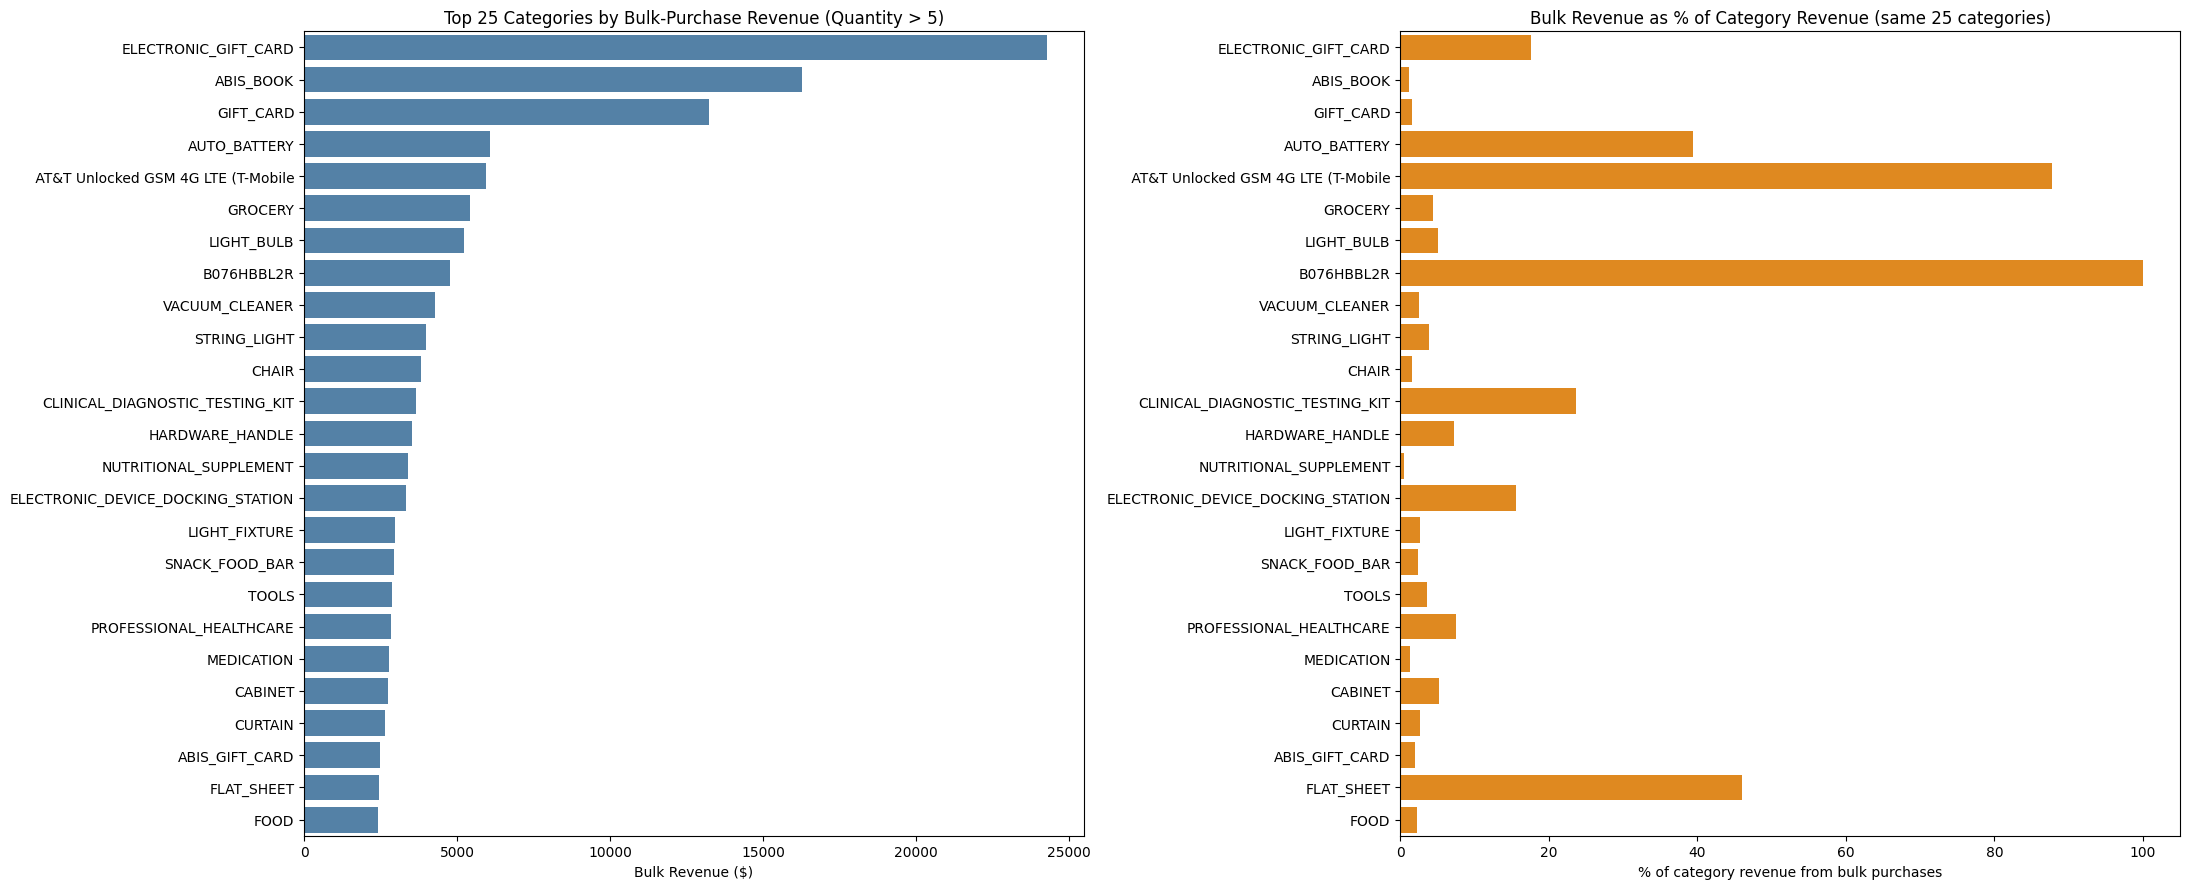

In [105]:
#Assess how bulk purchases affect revenue and supply chain operations
total_rev = merged_data.agg(spark_sum("Revenue")).collect()[0][0]
bulk_all = merged_data.filter(col("Quantity") > 5)
bulk_rev = bulk_all.agg(spark_sum("Revenue")).collect()[0][0] or 0
bulk_n = bulk_all.count()
total_n = merged_data.count()
print(f"Bulk line items: {bulk_n:,} ({bulk_n / total_n:.2%} of all line items)")
print(f"Bulk revenue: ${bulk_rev:,.2f} ({bulk_rev / total_rev:.2%} of total revenue)")


# Filter bulk purchases (Quantity > 5) and compute total revenue per category
bulk_by_cat = (
    bulk_all
    .filter(col("Category") != "Unknown")
    .groupBy("Category")
    .agg(
        spark_sum("Revenue").alias("Bulk_Revenue"),
        spark_sum("Quantity").alias("Bulk_Units"),
        count("*").alias("Bulk_Orders")
    )
)
cat_total = (
    merged_data
    .filter(col("Category") != "Unknown")
    .groupBy("Category")
    .agg(spark_sum("Revenue").alias("Category_Revenue"))
)

# Select the top 25 categories by total revenue
top25_bulk = (
    bulk_by_cat.join(cat_total, on="Category", how="left")
    .withColumn("Bulk_Share_%", col("Bulk_Revenue") / col("Category_Revenue") * 100)
    .orderBy(col("Bulk_Revenue").desc())
    .limit(25)
)

# Convert to Pandas for visualisation
bulk_pd = top25_bulk.toPandas()
print(bulk_pd[["Category", "Bulk_Revenue", "Bulk_Units", "Bulk_Orders", "Bulk_Share_%"]].round(1))


# Plot revenue from bulk purchases (Top 25 categories)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

sns.barplot(y="Category", x="Bulk_Revenue", data=bulk_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Top 25 Categories by Bulk-Purchase Revenue (Quantity > 5)")
axes[0].set_xlabel("Bulk Revenue ($)")
axes[0].set_ylabel("")

sns.barplot(y="Category", x="Bulk_Share_%", data=bulk_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Bulk Revenue as % of Category Revenue (same 25 categories)")
axes[1].set_xlabel("% of category revenue from bulk purchases")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2.8 Compare lifecycle strategies <font color = red>[5 marks]</font> <br>

Compare new and established products to inform and compare lifecycle strategies to make informed decisions.

   Launch_Year  Total_Revenue  Num_Products  Revenue_per_Product  Share_%
0         2018     11934381.1        157235                 75.9     27.2
1         2019      7842937.2        151337                 51.8     17.9
2         2020      8780085.2        197615                 44.4     20.0
3         2021      8421893.9        215291                 39.1     19.2
4         2022      6389249.4        192822                 33.1     14.6
5         2023       477104.2         16828                 28.4      1.1


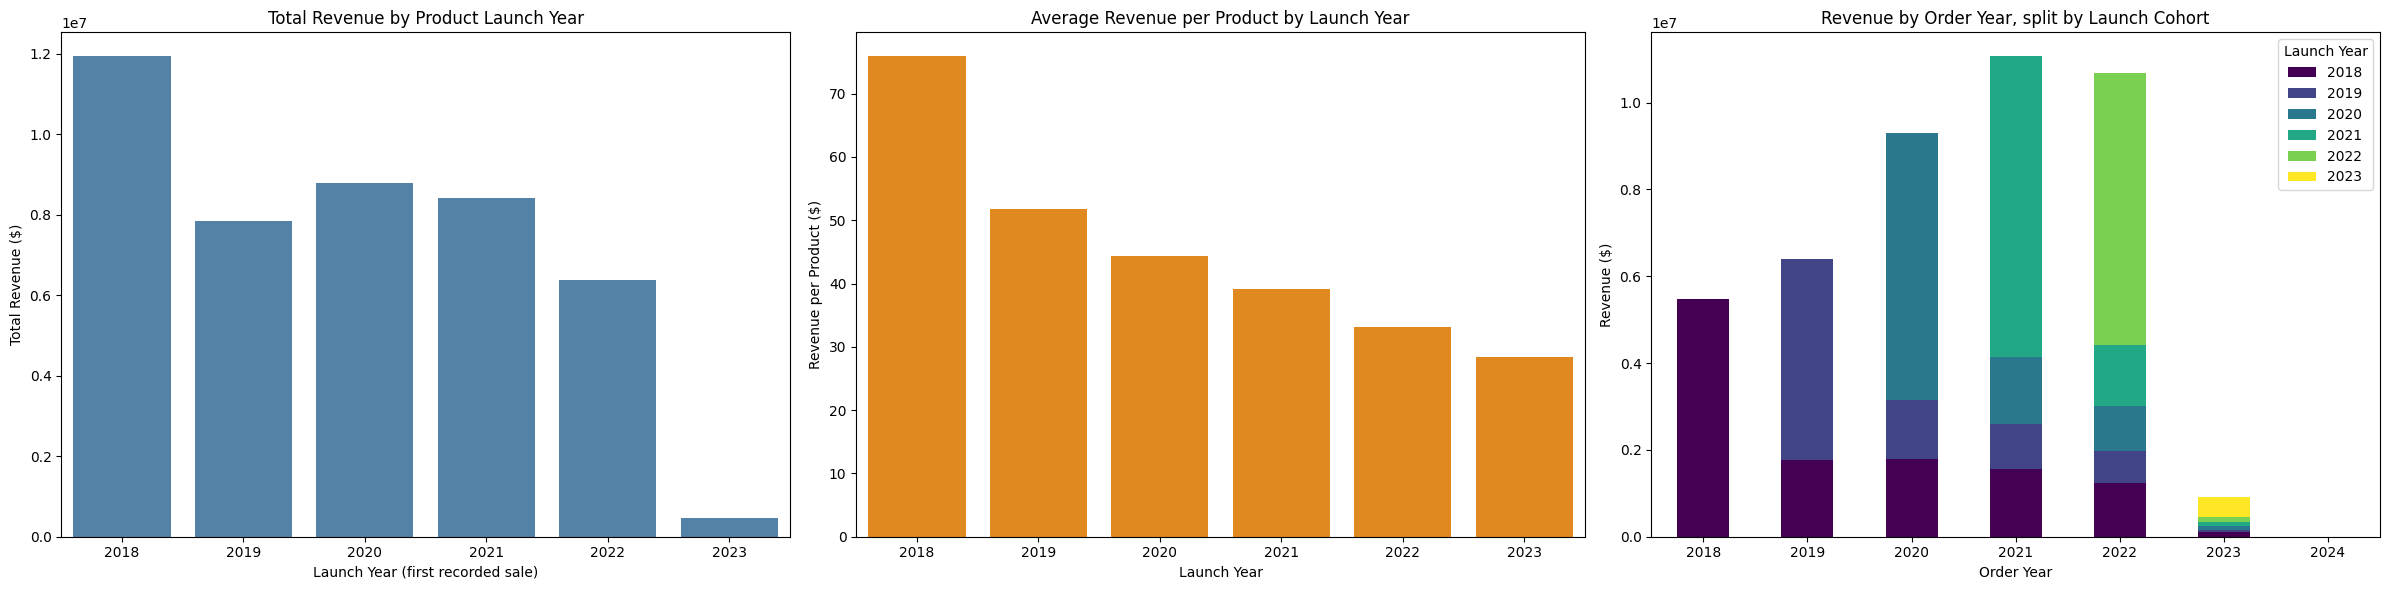

In [108]:
#Compare new and established products to inform lifecycle strategies

from pyspark.sql.functions import col, year, countDistinct, min as spark_min, sum as spark_sum
product_col = "ASIN/ISBN (Product Code)"

base = (
    merged_data
    .filter(col(product_col) != "Unknown")
    .withColumn("Order_Year", year(col("Order Date")))
)

# Compute "Launch Year" as the first recorded sale year for each product
launch = (
    base.groupBy(product_col)
    .agg(spark_min("Order_Year").alias("Launch_Year"))
)

# Join this back to the main dataset
with_launch = base.join(launch, on=product_col, how="inner")

# Now, we can compute revenue by launch year
launch_rev = (
    with_launch.groupBy("Launch_Year")
    .agg(
        spark_sum("Revenue").alias("Total_Revenue"),
        countDistinct(product_col).alias("Num_Products")
    )
    .withColumn("Revenue_per_Product", col("Total_Revenue") / col("Num_Products"))
    .orderBy("Launch_Year")
)
cohort_year = (
    with_launch.groupBy("Order_Year", "Launch_Year")
    .agg(spark_sum("Revenue").alias("Revenue"))
)

# Convert to Pandas
launch_pd = launch_rev.toPandas()
launch_pd["Share_%"] = launch_pd["Total_Revenue"] / launch_pd["Total_Revenue"].sum() * 100
print(launch_pd.round(1))

cohort_pd = cohort_year.toPandas()
cohort_pivot = cohort_pd.pivot_table(index="Order_Year", columns="Launch_Year",
                                     values="Revenue", fill_value=0).sort_index()

# Plot revenue vs. launch year
fig, axes = plt.subplots(1, 3, figsize=(24, 6))

sns.barplot(x="Launch_Year", y="Total_Revenue", data=launch_pd, ax=axes[0], color="steelblue")
axes[0].set_title("Total Revenue by Product Launch Year")
axes[0].set_xlabel("Launch Year (first recorded sale)")
axes[0].set_ylabel("Total Revenue ($)")

sns.barplot(x="Launch_Year", y="Revenue_per_Product", data=launch_pd, ax=axes[1], color="darkorange")
axes[1].set_title("Average Revenue per Product by Launch Year")
axes[1].set_xlabel("Launch Year")
axes[1].set_ylabel("Revenue per Product ($)")

cohort_pivot.plot(kind="bar", stacked=True, ax=axes[2], colormap="viridis")
axes[2].set_title("Revenue by Order Year, split by Launch Cohort")
axes[2].set_xlabel("Order Year")
axes[2].set_ylabel("Revenue ($)")
axes[2].legend(title="Launch Year")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

#5 Conclusion <font color = red>[10 marks]</font> <br>

Write your conclusion.

In [109]:
from pyspark.sql.functions import col, sum as spark_sum, count, countDistinct, dayofweek, month, year

total_rev = merged_data.agg(spark_sum("Revenue")).collect()[0][0]
n_cust = merged_data.filter(col("Survey ResponseID") != "Unknown").agg(countDistinct("Survey ResponseID")).collect()[0][0]
print(f"Rows: {merged_data.count():,} | Customers: {n_cust:,} | Revenue: ${total_rev:,.0f} | Avg spend/customer: ${total_rev/n_cust:,.2f}")

# Strongest/weakest weekday (avg sales per calendar day)
wd = (merged_data.withColumn("D", dayofweek("Order Date")).groupBy("D")
      .agg(spark_sum("Revenue").alias("S"), countDistinct("Order Date").alias("N"))
      .withColumn("Avg", col("S")/col("N")).orderBy(col("Avg").desc()))
wd.show()

# Top 3 months by revenue
merged_data.withColumn("M", month("Order Date")).groupBy("M").agg(spark_sum("Revenue").alias("R")).orderBy(col("R").desc()).show(3)

# Top 3 categories and states by revenue
merged_data.groupBy("Category").agg(spark_sum("Revenue").alias("R")).orderBy(col("R").desc()).show(3, truncate=False)
merged_data.groupBy("Shipping Address State").agg(spark_sum("Revenue").alias("R")).orderBy(col("R").desc()).show(3)

# Cluster profile
print(rfm_pd["Cluster"].value_counts().sort_index())
print(rfm_pd.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean().round(1))

Rows: 1,839,022 | Customers: 16,071 | Revenue: $43,866,629 | Avg spend/customer: $2,729.55
+---+-----------------+---+------------------+
|  D|                S|  N|               Avg|
+---+-----------------+---+------------------+
|  2|6823410.489999995|274| 24902.95799270071|
|  3|6650368.339999997|274|24271.417299270062|
|  4|6375856.479999999|273|23354.785641025635|
|  6|6164346.109999995|274|22497.613540145965|
|  1|6118267.609999996|272| 22493.63091911763|
|  5|6036843.809999994|274|22032.276678832095|
|  7|5697536.420000003|272| 20946.82507352942|
+---+-----------------+---+------------------+

+---+------------------+
|  M|                 R|
+---+------------------+
| 12| 4586934.009999578|
| 11| 4412152.139999651|
|  7|3824211.3699997244|
+---+------------------+
only showing top 3 rows
+---------+------------------+
|Category |R                 |
+---------+------------------+
|Unknown  |2316276.9199999594|
|ABIS_BOOK|1347983.4000000285|
|GIFT_CARD|866770.5299999994 |
+-----

# 5. Conclusion

## Summary
I used PySpark to analyse 1.85M Amazon purchase records joined to survey demographics. After cleaning (median/"Unknown" imputation, 11,695 duplicates removed, feature engineering) I explored purchase patterns, segmented customers with RFM and K-Means (k = 4), and derived business insights.

## Key Findings
- **Trends:** Purchases grew from 224,259 (2018) to a peak of 464,639 (2021). November (10.1%) and December (10.5%) are the strongest months for revenue.
- **Weekdays:** Monday is the strongest day ($24,903 per day) and Saturday the weakest ($20,947), a gap of 19%. Weekends average 7% less revenue per day than weekdays.
- **Customers:** Mean spend per customer is $2,729 against a median of $56, so a few heavy buyers drive revenue. Only 53.9% of customers bought on more than one day. Purchases per customer rise with income (249 to 523) and are higher for female customers (405 vs 310).
- **Products and states:** Books, gift cards and pet food lead revenue, but the top 25 categories give only 23.6%, so sales are widely spread. CA, TX, FL and NY lead, mostly because of population (customers vs revenue by state, r = 0.99).
- **Segments (k = 4, chosen where WCSS flattens after 4):**
  - Champions: 21.6% of customers, 414 products, $11,609 average spend.
  - Regular buyers: 12.0%, 45 products, $1,519.
  - Recent low-value: 33.3%, about 1 product, $66.
  - Lapsed one-timers: 33.1%, about 1 product, $66, last purchase around 1,600 days ago.
  - Income is a weak predictor of segment.
- **Risk and operations:** 20,437 transactions (1.1%) exceed $171.70 (mean + 3 SD); they need review, not automatic fraud labelling. Bulk purchases are only 0.71% of revenue. Revenue per product falls for newer launch cohorts ($75.9 for 2018 vs $28.4 for 2023).

## Recommendations
1. Run promotions on Mondays and before November and December peaks.
2. Re-engage the 7,402 one-day customers and reward the 3,760 customers active on 50+ days.
3. Protect CA, TX, FL and NY, and invest in fast-growing states such as HI, AK, VT and NV.
4. Stock ahead of peaks for volatile categories (TV, toys, tablets, laptops); keep steady replenishment for stable ones.
5. Review flagged high-value transactions manually, ideally with category-specific thresholds.

## Limitations
- No time-of-day data, so day of month replaced the hourly analysis.
- Some CSV rows are misaligned, and one stray 2024 record sets the latest date (see the issue below).
- `dropDuplicates()` may remove genuine repeat purchases, and launch year is a proxy.